# Part (a): Time-series preprocessing

Gap filling, transformations, and temporal features affect both forecast accuracy and the information a forecast is allowed to use. This chapter compares those choices on the Wanshouxigong series audited in the [EDA chapter](01_time_series_eda.ipynb). PM2.5 is the primary target and receives every comparison in full; PM10, the secondary target, runs through the same code with parameters fitted on its own training data, and its results sit beside PM2.5's in the same tables. The other numeric variables enter the Granger tests and serve as lagged forecast covariates.

The sections follow their dependencies. Artificial gaps choose a filling method, which completes the training series needed by the stationarity tests, decompositions, and Granger tests. The stationarity section decides which version of each variable the Granger tests use, decomposition supplies the deseasonalized series for anomaly detection and a seasonal profile for the forecast, and the Granger results propose a covariate set that the forecast section tests on validation data. Every fitted parameter comes from the training interval, model choices use the validation interval, and the test interval is scored once, at the end.

## Load the environment

The setup cell imports shared paths, the seed, and the analysis libraries, and records the package versions that affect the results. Inputs are reloaded explicitly so the notebook runs in a fresh kernel. Instead of one shared random generator, each stochastic step creates its own generator or estimator from `RANDOM_STATE`, so no result depends on which cells ran before it.

In [1]:
import platform
import warnings
from importlib.metadata import version

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import holidays
from IPython.display import display
from scipy import stats
from statsmodels.tsa.api import VAR
from statsmodels.tsa.stattools import acf, adfuller, grangercausalitytests, kpss
from statsmodels.tsa.seasonal import MSTL, STL, seasonal_decompose
from statsmodels.stats.multitest import multipletests
from arch.unitroot import PhillipsPerron
from arch.utility.exceptions import InfeasibleTestException
from sklearn.ensemble import IsolationForest, RandomForestRegressor
from sklearn.metrics import mean_absolute_error, root_mean_squared_error

from preprocessing import PROCESSED_DATA_DIR, RAW_DATA_DIR, RANDOM_STATE

sns.set_theme(style="whitegrid")
package_versions = {
    name: version(name)
    for name in ["numpy", "pandas", "scipy", "statsmodels", "arch", "scikit-learn", "holidays"]
}
package_versions["python"] = platform.python_version()
print(f"Random seed: {RANDOM_STATE}")
print(f"Raw data directory: {RAW_DATA_DIR}")
display(pd.Series(package_versions, name="version").to_frame())

Random seed: 42
Raw data directory: D:\HCMUS\DataMining\preprocessing\data\raw


,version
numpy,2.5.5
pandas,3.1.1
scipy,1.18.1
statsmodels,0.15.0
arch,9.0.0
scikit-learn,1.9.1
holidays,0.109
python,3.12.13


## Prepare data

The setup reloads the checksum-verified archive independently of the [EDA chapter](01_time_series_eda.ipynb) and reuses its station, Wanshouxigong, and its boundaries: training before 2015-03-01, validation from 2015-03-01 to before 2016-03-01, and testing from 2016-03-01 on. Timestamps remain naive local Beijing civil time (UTC+8), all variables share the hourly grid, and the checks below leave the source values and native gaps unchanged.

`wind_components` converts the compass label `wd` and the speed WSPM into $u = -s\sin\theta$ and $v = -s\cos\theta$, using the EDA chapter's convention: $s$ is WSPM in m/s and $\theta$ is the direction the wind blows from, clockwise from north. Calm air has no direction, so a zero speed gives $u=v=0$ even without a label; otherwise a missing label or speed leaves both components missing. Each hour's components use only that hour's values, so computing them before the split cannot leak information between intervals.

`training_domain` reports each Granger candidate's training minimum and its share of zero values. It determines where $\log(x)$ and Box-Cox are defined in the stationarity section and informs the RAIN decision in the Granger section, and `granger_pair_counts` shows how many directed pairs the 12 candidates give with and without RAIN.

The PACF search ceiling and the candidate lag orders repeat the protocol of the [EDA chapter](01_time_series_eda.ipynb), which justifies them. The ceiling is $L=\min(10\log_{10} n, n/5)$, rounded down and capped at $\lfloor n/2 \rfloor - 1$, the largest lag the PACF helper accepts, where $n$ is the target's number of observed training hours; this rule-of-thumb limit covers the 24-hour cycle with lags to spare, and the BIC order does not change for ceilings from 24 to 72 hours. `lag_screening` shows that neither the $n/5$ term nor the cap binds here. The screened order `p_reference` is the last lag whose gap-aware training PACF crosses its $\pm 1.96/\sqrt{n_k}$ band, where $n_k$ is the number of observed pairs $k$ hours apart. With tens of thousands of hours this band is narrow, so `p_reference` can reach $L$, which then signals small dependence beyond the search range rather than a PACF cutoff. `bic_p` is therefore computed as well, as the BIC order over AR(0) to AR(`max_lag`) on one common sample of complete lag windows. The forecast section compares both orders alongside a fixed grid on the validation interval, and since $L$ also bounds the lag features, no span longer than $L$ hours is tested. The gap-aware training ACF and PACF also serve as the reference for the filling comparison in the next section.

In [2]:
from preprocessing.air_quality import (
    add_timestamp, chronological_split, download_air_quality, read_stations, wind_components,
)
from preprocessing.time_series import (
    ar_information_criteria, compare_filled_dependence, fill_gaps, gap_aware_ljung_box,
    gap_aware_pacf, pacf_lag_order, seeded_gap_mask, trailing_window_features,
)

SELECTED_STATION = "Wanshouxigong"
TARGET_COLUMNS = ["PM2.5", "PM10"]
COVARIATE_COLUMNS = ["SO2", "NO2", "CO", "O3", "TEMP", "PRES", "DEWP", "RAIN", "WSPM"]
# u and v replace wd and WSPM in the Granger tests, as in the EDA chapter.
GRANGER_CANDIDATE_COLUMNS = TARGET_COLUMNS + [
    "SO2", "NO2", "CO", "O3", "TEMP", "PRES", "DEWP", "RAIN", "u", "v",
]
VALIDATION_START = pd.Timestamp("2015-03-01")
TEST_START = pd.Timestamp("2016-03-01")

stations = add_timestamp(read_stations(download_air_quality(RAW_DATA_DIR)))
selected = stations.loc[stations["station"].eq(SELECTED_STATION)].set_index("timestamp")
assert selected.index.is_monotonic_increasing and selected.index.is_unique
assert selected.index.equals(pd.date_range(selected.index.min(), selected.index.max(), freq="h"))
selected = selected.asfreq("h")
selected = selected.join(wind_components(selected["wd"], selected["WSPM"]))
train, validation, test = chronological_split(
    selected, validation_start=VALIDATION_START, test_start=TEST_START,
)
native_missing_by_split = pd.DataFrame(
    {name: part[TARGET_COLUMNS + COVARIATE_COLUMNS + ["wd", "u", "v"]].isna().sum()
     for name, part in {"train": train, "validation": validation, "test": test}.items()}
)
training_domain = pd.DataFrame(
    {
        "observed_hours": train[GRANGER_CANDIDATE_COLUMNS].notna().sum(),
        "minimum": train[GRANGER_CANDIDATE_COLUMNS].min(),
        "zero_share": {c: float(train[c].dropna().eq(0).mean()) for c in GRANGER_CANDIDATE_COLUMNS},
    }
)
training_domain["log_and_box_cox_defined"] = training_domain["minimum"] > 0
granger_pair_counts = pd.Series(
    {
        "with RAIN": len(GRANGER_CANDIDATE_COLUMNS) * (len(GRANGER_CANDIDATE_COLUMNS) - 1),
        "without RAIN": (len(GRANGER_CANDIDATE_COLUMNS) - 1) * (len(GRANGER_CANDIDATE_COLUMNS) - 2),
    },
    name="directed_pairs",
)

observed_training_hours = {target: int(train[target].notna().sum()) for target in TARGET_COLUMNS}
rule_max_lag = {t: int(min(10 * np.log10(n), n / 5)) for t, n in observed_training_hours.items()}
# gap_aware_pacf requires max_lag below half the observed count.
MAX_LAG_BY_TARGET = {t: min(rule_max_lag[t], n // 2 - 1) for t, n in observed_training_hours.items()}
gap_reference = {target: gap_aware_pacf(train[target], MAX_LAG_BY_TARGET[target]) for target in TARGET_COLUMNS}
p_reference = {target: pacf_lag_order(gap_reference[target]) for target in TARGET_COLUMNS}
# BIC over AR(0..max_lag) on one common sample of complete lag windows, as in the EDA chapter.
bic_reference = {
    target: int(ar_information_criteria(train[target], MAX_LAG_BY_TARGET[target])["bic"].idxmin())
    for target in TARGET_COLUMNS
}
lag_screening = pd.DataFrame(
    {
        "observed_training_hours": observed_training_hours,
        "rule_max_lag": rule_max_lag,
        "n_over_5_binds": {t: n / 5 < 10 * np.log10(n) for t, n in observed_training_hours.items()},
        "pacf_helper_cap_binds": {t: MAX_LAG_BY_TARGET[t] < rule_max_lag[t] for t in TARGET_COLUMNS},
        "max_lag": MAX_LAG_BY_TARGET,
        "p_reference": p_reference,
        "p_at_search_ceiling": {t: p_reference[t] == MAX_LAG_BY_TARGET[t] for t in TARGET_COLUMNS},
        "bic_p": bic_reference,
    }
)
display(native_missing_by_split)
display(training_domain)
display(granger_pair_counts.to_frame())
display(lag_screening)

,train,validation,test
PM2.5,257,227,212
PM10,179,127,178
SO2,384,112,173
NO2,437,138,179
CO,930,130,237
O3,792,109,177
TEMP,1,0,18
PRES,1,0,18
DEWP,1,0,18
RAIN,1,0,18


,observed_hours,minimum,zero_share,log_and_box_cox_defined
PM2.5,17263,3.000000,0.000000,True
PM10,17341,2.000000,0.000000,True
SO2,17136,0.285600,0.000000,True
NO2,17083,2.000000,0.000000,True
CO,16590,100.000000,0.000000,True
O3,16728,0.214200,0.000000,True
TEMP,17519,-11.000000,0.009361,False
PRES,17519,985.100000,0.000000,True
DEWP,17519,-31.300000,0.001770,False
RAIN,17519,0.000000,0.966836,False


,directed_pairs
with RAIN,132
without RAIN,110


,observed_training_hours,rule_max_lag,n_over_5_binds,pacf_helper_cap_binds,max_lag,p_reference,p_at_search_ceiling,bic_p
PM2.5,17263,42,False,False,42,39,False,2
PM10,17341,42,False,False,42,42,True,2


## Compare gap-filling methods

Artificial gaps provide known ground truth for comparing reconstruction methods. `seeded_gap_mask` hides exactly 5% of a target's observed training hours, choosing them without looking at their values and never touching a native gap. Each call creates its own generator from `RANDOM_STATE`, so every method sees the same mask regardless of cell order, and PM10 gets its own mask over its own observed hours from the same seed.

The 5% rate is a declared choice, not a tuned one. It is several times the native training missing rate, {eval}`f"{native_missing_by_split.loc['PM2.5', 'train'] / len(train):.1%}"` for PM2.5 and {eval}`f"{native_missing_by_split.loc['PM10', 'train'] / len(train):.1%}"` for PM10 (`native_missing_by_split`), so each method fills more gaps than it will meet in practice and is scored on several hundred hidden hours per target (`hidden` in `gap_fill_comparison`), while most of the series stays observed and the methods keep the neighbours they rely on. Other rates are not compared; a higher rate would remove more neighbours and could change the ranking.

Two mask designs are compared, and each mask is reused for every method:

- Point mask: single hours drawn uniformly without replacement, so the hidden hours are missing completely at random (MCAR). Every observed hour has the same chance of being scored whatever its value, so no method benefits from a mask that happens to fall in quiet periods or in episodes.
- Block mask: contiguous runs whose lengths are drawn from the target's native training gap lengths, placed at random among observed hours until 5% are hidden. Point gaps usually leave both neighbours observed, which favours interpolation, whereas native gaps are longer; since the selected method will fill native gaps, this design is closer to its real use.

`fill_gaps` defines the five methods. Each fills native and artificial gaps together, but only artificial gaps are scored.

| Method | Definition | Uses later observations |
|---|---|---|
| Forward fill | Last observed value | No |
| Linear | Straight line between the nearest observed hours on each side | Yes |
| Polynomial, order $d \in \{2, 3\}$ | Least-squares polynomial of degree $d$ fitted to the $d$ nearest observed hours on each side, evaluated at the missing hour | Yes |
| Cubic spline | One not-a-knot cubic spline through all observed training hours | Yes |

The polynomial methods are deliberately local. Pandas `interpolate(method="polynomial", order=3)` would fit a spline through all points and return the same values as `method="cubicspline"`, duplicating the cubic spline row.

A method leaves an hour unfilled when it lacks the observations it needs, for example before the first observation or without $d$ observed hours on both sides. The table reports each method's unfillable count per mask, and all methods are scored on the common set $S$ of masked hours that every method fills. With $e_t = \hat{y}_t - y_t$, where $\hat{y}_t$ is the filled value and $y_t$ the hidden observation at hour $t$,

$$\mathrm{MAE} = \frac{1}{|S|}\sum_{t \in S} |e_t|, \qquad \mathrm{RMSE} = \sqrt{\frac{1}{|S|}\sum_{t \in S} e_t^2},$$

both in µg/m³. RMSE weights large errors more heavily, which matters during pollution episodes. The selection rule was fixed before the results were seen: within each target and mask design the methods are ranked by RMSE, the method with the lowest mean rank over the four combinations is selected, and ties are broken by the worst rank.

The Ljung-Box test checks whether reconstruction errors are autocorrelated. $e_t$ stays on the hourly grid and is missing outside $S$, so lag $k$ always means $k$ hours, and `gap_aware_ljung_box` computes

$$Q(h) = \frac{n+2}{n}\sum_{k=1}^{h} n_k \hat{\rho}_k^2,$$

where $n$ is the number of scored errors, $n_k$ the number of scored pairs exactly $k$ hours apart, and $\hat{\rho}_k$ their pair-adjusted autocorrelation; on a complete series this equals the classical statistic. The null hypothesis is that the errors are uncorrelated at lags 1 to $h$, tested against a $\chi^2_h$ distribution with $h = 24$ hours and $\alpha = 0.05$. Correlated errors mean a method repeats the same kind of mistake over neighbouring hours, as forward fill does during a rising episode. The table also reports the smallest $n_k$, because the point mask produces few close pairs and its test therefore has less power than the block test.

Reconstruction accuracy on past data does not make a method suitable for forecasting, because four of the five methods read observations after the gap.

,runs,mean_hours,median_hours,max_hours
PM2.5 native,70.0,3.67,1.0,26.0
PM10 native,46.0,3.89,1.0,26.0
PM2.5 point,810.0,1.07,1.0,3.0
PM2.5 block,213.0,4.05,2.0,26.0
PM10 point,822.0,1.05,1.0,3.0
PM10 block,231.0,3.75,1.0,26.0


hidden  unfillable  scored     mae    rmse  \
target mask  method                                                     
PM2.5  point ffill            863           0     862  12.632  21.816   
             linear           863           0     862   7.859  13.897   
             polynomial_2     863           1     862   7.809  13.475   
             polynomial_3     863           1     862   8.637  14.959   
             cubic_spline     863           0     862   7.919  12.775   
       block ffill            863           0     863  37.662  76.114   
             linear           863           0     863  25.338  41.597   
             polynomial_2     863           0     863  34.374  57.730   
             polynomial_3     863           0     863  30.431  49.937   
             cubic_spline     863           0     863  35.992  64.713   
PM10   point ffill            867           0     867  24.373  43.016   
             linear           867           0     867  17.090  31.714   
             polynomial_2     867           0     867  17.903  33.018   
             polynomial_3     867           0     867  18.504  33.256   
             cubic_spline     867           0     867  19.335  35.110   
       block ffill            867           0     867  57.400  86.982   
             linear           867           0     867  38.145  58.781   
             polynomial_2     867           0     867  48.890  74.829   
             polynomial_3     867           0     867  47.611  74.755   
             cubic_spline     867           0     867  61.385  94.699   

                           mean_error   lb_stat  lb_pvalue  min_pair_count  \
target mask  method                                                          
PM2.5  point ffill             -0.324   147.379      0.000              33   
             linear             0.334   112.488      0.000              33   
             polynomial_2       0.376    72.516      0.000              33   
             polynomial_3       0.231    95.896      0.000              33   
             cubic_spline       0.390   113.598      0.000              33   
       block ffill              3.263  4572.806      0.000              62   
             linear            -0.333  2741.630      0.000              62   
             polynomial_2       0.481  4242.334      0.000              62   
             polynomial_3      -2.252  3203.462      0.000              62   
             cubic_spline       6.015  4981.585      0.000              62   
PM10   point ffill             -2.686    83.670      0.000              34   
             linear            -1.436    29.158      0.214              34   
             polynomial_2      -2.009    54.411      0.000              34   
             polynomial_3      -1.136    28.783      0.228              34   
             cubic_spline      -2.341    76.789      0.000              34   
       block ffill             16.443  3916.966      0.000              40   
             linear             7.273  2136.787      0.000              40   
             polynomial_2      15.963  3323.341      0.000              40   
             polynomial_3       8.802  3483.008      0.000              40   
             cubic_spline      18.234  3397.263      0.000              40   

                           uses_later_observations  lb_reject  rmse_rank  
target mask  method                                                       
PM2.5  point ffill                           False       True        5.0  
             linear                           True       True        3.0  
             polynomial_2                     True       True        2.0  
             polynomial_3                     True       True        4.0  
             cubic_spline                     True       True        1.0  
       block ffill                           False       True        5.0  
             linear                           True       True        1.0  
             polynomial_2   

,mean_rmse_rank,worst_rmse_rank
method,,
linear,1.50,3.0
polynomial_2,2.50,3.0
polynomial_3,2.75,4.0
cubic_spline,3.50,5.0
ffill,4.75,5.0


Selected filling method: linear


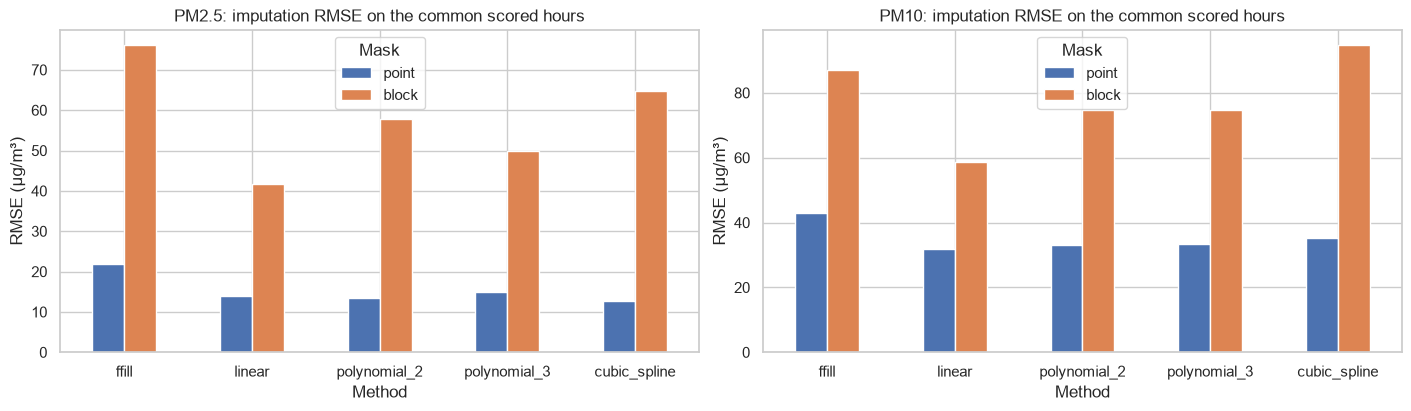

In [3]:
GAP_FRACTION = 0.05
LJUNG_BOX_LAG = 24
ALPHA = 0.05
FILL_SPECS = {
    "ffill": ("ffill", {}),
    "linear": ("linear", {}),
    "polynomial_2": ("polynomial", {"order": 2}),
    "polynomial_3": ("polynomial", {"order": 3}),
    "cubic_spline": ("cubic_spline", {}),
}
USES_LATER_OBSERVATIONS = {"ffill": False, "linear": True, "polynomial_2": True,
                           "polynomial_3": True, "cubic_spline": True}


def run_lengths(flags):
    """Lengths in hours of the runs of consecutive True values in a boolean Series."""
    runs = flags.groupby((flags != flags.shift()).cumsum()).agg(["first", "size"])
    return runs.loc[runs["first"], "size"].to_numpy()


gap_masks = {}
gap_fill_rows = []
gap_errors = {}
for target in TARGET_COLUMNS:
    series = train[target]
    native_lengths = run_lengths(series.isna())
    masks = {
        "point": seeded_gap_mask(series, GAP_FRACTION, RANDOM_STATE),
        "block": seeded_gap_mask(series, GAP_FRACTION, RANDOM_STATE, block_lengths=native_lengths),
    }
    for design, hidden in masks.items():
        gap_masks[(target, design)] = hidden
        masked = series.mask(hidden)
        filled = {name: fill_gaps(masked, method, **kw) for name, (method, kw) in FILL_SPECS.items()}
        # Score every method on the hidden hours that all methods can fill.
        scored = hidden & pd.concat([f.notna() for f in filled.values()], axis=1).all(axis=1)
        for name, values in filled.items():
            error = (values - series).where(scored)
            gap_errors[(target, design, name)] = error
            ljung_box = gap_aware_ljung_box(error, LJUNG_BOX_LAG)
            gap_fill_rows.append(
                {
                    "target": target, "mask": design, "method": name,
                    "hidden": int(hidden.sum()),
                    "unfillable": int((hidden & values.isna()).sum()),
                    "scored": int(scored.sum()),
                    "mae": float(error.abs().mean()),
                    "rmse": float(np.sqrt((error**2).mean())),
                    "mean_error": float(error.mean()),
                    "lb_stat": float(ljung_box["lb_stat"].iloc[-1]),
                    "lb_pvalue": float(ljung_box["lb_pvalue"].iloc[-1]),
                    "min_pair_count": int(ljung_box["pair_counts"].min()),
                    "uses_later_observations": USES_LATER_OBSERVATIONS[name],
                }
            )
gap_fill_comparison = pd.DataFrame(gap_fill_rows).set_index(["target", "mask", "method"])
gap_fill_comparison["lb_reject"] = gap_fill_comparison["lb_pvalue"] < ALPHA
gap_fill_comparison["rmse_rank"] = gap_fill_comparison.groupby(["target", "mask"])["rmse"].rank()

# Hidden block lengths, to compare the block design with the native gaps it imitates.
run_summary = ["count", "mean", "50%", "max"]
mask_run_lengths = pd.DataFrame(
    {f"{target} native": pd.Series(run_lengths(train[target].isna())).describe()[run_summary]
     for target in TARGET_COLUMNS}
    | {f"{target} {design}": pd.Series(run_lengths(mask)).describe()[run_summary]
       for (target, design), mask in gap_masks.items()}
).T.rename(columns={"count": "runs", "mean": "mean_hours", "50%": "median_hours", "max": "max_hours"})
display(mask_run_lengths.round(2))
display(gap_fill_comparison.round(3))

# Selection rule, stated before the comparison: lowest mean RMSE rank over both targets and both masks.
fill_selection = (
    gap_fill_comparison.groupby("method")
    .agg(mean_rmse_rank=("rmse_rank", "mean"), worst_rmse_rank=("rmse_rank", "max"))
    .sort_values(["mean_rmse_rank", "worst_rmse_rank"])
)
SELECTED_FILL = fill_selection.index[0]
display(fill_selection)
print(f"Selected filling method: {SELECTED_FILL}")

fig, axes = plt.subplots(1, 2, figsize=(14, 4), constrained_layout=True)
for ax, target in zip(axes, TARGET_COLUMNS):
    table = gap_fill_comparison.xs(target, level="target")["rmse"].unstack("mask")[["point", "block"]]
    table.loc[list(FILL_SPECS)].plot.bar(ax=ax, rot=0)
    ax.set(title=f"{target}: imputation RMSE on the common scored hours", xlabel="Method",
           ylabel="RMSE (µg/m³)")
    ax.legend(title="Mask")
plt.show()

# Values quoted in the interpretation; the assertions guard its qualitative claims.
gap_rmse = gap_fill_comparison["rmse"].unstack("method")
gap_lb_p = gap_fill_comparison["lb_pvalue"].unstack("method")
gap_bias = gap_fill_comparison["mean_error"].unstack("method")
point_best = {t: gap_rmse.loc[(t, "point")].idxmin() for t in TARGET_COLUMNS}
block_to_point = {t: gap_rmse.loc[(t, "block"), SELECTED_FILL] / gap_rmse.loc[(t, "point"), SELECTED_FILL]
                  for t in TARGET_COLUMNS}
lb_not_rejected = ", ".join(
    f"{method} ({target}, {design} mask)"
    for target, design, method in gap_fill_comparison.index[~gap_fill_comparison["lb_reject"]]
)
assert (gap_rmse.xs("block", level="mask").idxmin(axis=1) == SELECTED_FILL).all()
assert (gap_rmse.xs("block", level="mask").idxmax(axis=1).isin(["ffill", "cubic_spline"])).all()
assert gap_fill_comparison.xs("block", level="mask")["lb_reject"].all()
for target in TARGET_COLUMNS:
    native, block = mask_run_lengths.loc[f"{target} native"], mask_run_lengths.loc[f"{target} block"]
    assert native["max_hours"] == block["max_hours"] and abs(native["mean_hours"] - block["mean_hours"]) < 1
assert gap_fill_comparison["unfillable"].max() <= 1

The rule selects {eval}`SELECTED_FILL` interpolation, with a mean RMSE rank of {eval}`f"{fill_selection.loc[SELECTED_FILL, 'mean_rmse_rank']:.2f}"` and a worst rank of {eval}`int(fill_selection.loc[SELECTED_FILL, 'worst_rmse_rank'])` (`fill_selection`), but the two mask designs tell different stories.

On the point mask, every method except forward fill reconstructs isolated hours about equally well, because a single missing hour sits between two observed neighbours and any method that uses both sides lands close to the truth. For PM2.5 the lowest RMSE belongs to {eval}`point_best["PM2.5"]` ({eval}`f"{gap_rmse.loc[('PM2.5', 'point'), point_best['PM2.5']]:.1f}"` µg/m³) against {eval}`f"{gap_rmse.loc[('PM2.5', 'point'), 'linear']:.1f}"` for linear and {eval}`f"{gap_rmse.loc[('PM2.5', 'point'), 'ffill']:.1f}"` for forward fill; for PM10 the best is {eval}`point_best["PM10"]` ({eval}`f"{gap_rmse.loc[('PM10', 'point'), point_best['PM10']]:.1f}"` µg/m³).

The block mask is harder and separates the methods. Linear RMSE rises by a factor of {eval}`f"{block_to_point['PM2.5']:.1f}"` for PM2.5 and {eval}`f"{block_to_point['PM10']:.1f}"` for PM10, yet linear is still the best method on blocks for both targets ({eval}`f"{gap_rmse.loc[('PM2.5', 'block'), 'linear']:.1f}"` and {eval}`f"{gap_rmse.loc[('PM10', 'block'), 'linear']:.1f}"` µg/m³). The cubic spline falls to {eval}`f"{gap_rmse.loc[('PM2.5', 'block'), 'cubic_spline']:.1f}"` and {eval}`f"{gap_rmse.loc[('PM10', 'block'), 'cubic_spline']:.1f}"` µg/m³, with mean errors of {eval}`f"{gap_bias.loc[('PM2.5', 'block'), 'cubic_spline']:+.1f}"` and {eval}`f"{gap_bias.loc[('PM10', 'block'), 'cubic_spline']:+.1f}"` µg/m³, because a spline or local cubic fitted around a multi-hour gap follows the local slope and overshoots inside the gap, which a straight line cannot do. Native and block runs have similar mean lengths and the same maximum (`mask_run_lengths`), so the block result is the more relevant one for completing native gaps, and that is where linear interpolation wins clearly.

Almost all reconstruction errors are autocorrelated: every method rejects the Ljung-Box null on the block mask at $\alpha = 0.05$, because errors inside a block share a sign when the whole block is reconstructed from the same two neighbours. On the point mask the test fails to reject only for {eval}`lb_not_rejected`, and with a smallest pair count of {eval}`int(gap_fill_comparison['min_pair_count'].xs('point', level='mask').min())` that test has little power, so a non-rejection is weak evidence of uncorrelated errors. Unfillable counts are at most {eval}`int(gap_fill_comparison['unfillable'].max())` hour per method and mask, so the common scored set loses almost nothing.

Because linear interpolation reads the observation after each gap, it is a retrospective method. It completes the training series for the stationarity tests, decompositions, and Granger tests, but forecast inputs never use it; they use a causal forward fill instead (see the feature section). The mask is also MCAR by construction, while the [EDA chapter](01_time_series_eda.ipynb) found native gaps clustered in time and shared across stations, so these scores describe reconstruction under random placement rather than under the outages that produced the native gaps.

### Complete the training series and check dependence

`SELECTED_FILL` completes the native gaps of every Granger candidate on the training interval. Interpolation cannot fill hours before a variable's first observation or after its last, so such hours would be trimmed from the ends of the interval rather than extrapolated; `trimmed_span` reports how many are removed, and `fill_summary` counts the filled hours per variable. Each variable is filled independently, so a filled hour of one variable can sit next to an observed hour of another.

Because filling changes the series that later sections analyse, `compare_filled_dependence` compares the completed targets with the gap-aware reference on identical timestamps. It rejects altered observed values, shifted grids, or remaining gaps, and reports the largest absolute ACF and PACF changes over lags 1 to `max_lag`, the band-rule orders `p_gap` and `p_filled`, and whether they agree. The BIC order is also recomputed on the completed series, and the gap-aware ACF remains the reference for the observed data.

In [4]:
fill_method, fill_kwargs = FILL_SPECS[SELECTED_FILL]
completed_training = pd.DataFrame(
    {column: fill_gaps(train[column], fill_method, **fill_kwargs) for column in GRANGER_CANDIDATE_COLUMNS}
)
# Hours before the first or after the last observation cannot be interpolated; trim them.
complete_hours = completed_training.notna().all(axis=1)
filled_start, filled_end = complete_hours.idxmax(), complete_hours[::-1].idxmax()
chosen_filled_training = completed_training.loc[filled_start:filled_end]
assert chosen_filled_training.notna().all().all()
assert chosen_filled_training.index.equals(pd.date_range(filled_start, filled_end, freq="h"))
fill_summary = pd.DataFrame(
    {
        "native_missing": train[GRANGER_CANDIDATE_COLUMNS].isna().sum(),
        "filled": (train[GRANGER_CANDIDATE_COLUMNS].isna() & completed_training.notna()).sum(),
        "left_unfilled": completed_training.isna().sum(),
    }
)
trimmed_span = pd.Series(
    {
        "method": SELECTED_FILL,
        "start": filled_start,
        "end_inclusive": filled_end,
        "hours_kept": len(chosen_filled_training),
        "hours_trimmed": len(train) - len(chosen_filled_training),
    },
    name="value",
)
display(fill_summary)
display(trimmed_span.to_frame())

chosen_fill_dependence_check = pd.DataFrame(
    {
        target: compare_filled_dependence(
            train[target].loc[filled_start:filled_end], chosen_filled_training[target],
            MAX_LAG_BY_TARGET[target],
        )
        | {
            "bic_gap": bic_reference[target],
            "bic_filled": int(
                ar_information_criteria(chosen_filled_training[target], MAX_LAG_BY_TARGET[target])["bic"].idxmin()
            ),
        }
        for target in TARGET_COLUMNS
    }
).T
chosen_fill_dependence_check["same_bic_p"] = (
    chosen_fill_dependence_check["bic_gap"] == chosen_fill_dependence_check["bic_filled"]
)
display(chosen_fill_dependence_check)
assert trimmed_span["hours_trimmed"] == 0
assert chosen_fill_dependence_check["same_p"].all() and chosen_fill_dependence_check["same_bic_p"].all()
largest_fill_share = (fill_summary["filled"] / len(train)).sort_values(ascending=False)
assert (fill_summary.loc[TARGET_COLUMNS, "filled"] / len(train)).max() < 0.02

,native_missing,filled,left_unfilled
PM2.5,257,257,0
PM10,179,179,0
SO2,384,384,0
NO2,437,437,0
CO,930,930,0
O3,792,792,0
TEMP,1,1,0
PRES,1,1,0
DEWP,1,1,0
RAIN,1,1,0


,value
method,linear
start,2013-03-01 00:00:00
end_inclusive,2015-02-28 23:00:00
hours_kept,17520
hours_trimmed,0


,max_abs_acf_difference,max_abs_pacf_difference,p_gap,p_filled,same_p,bic_gap,bic_filled,same_bic_p
PM2.5,0.01375,0.054134,39,39,True,2,2,True
PM10,0.012184,0.022109,42,42,True,2,2,True


Every Granger candidate is observed at the first and last training hour, so linear interpolation fills all native gaps, no hour is trimmed (`trimmed_span`), and the completed interval keeps all {eval}`f"{int(trimmed_span['hours_kept']):,}"` hours. The most heavily filled variable is {eval}`largest_fill_share.index[0]`, with {eval}`f"{largest_fill_share.iloc[0]:.1%}"` of its training hours interpolated, followed by {eval}`largest_fill_share.index[1]` at {eval}`f"{largest_fill_share.iloc[1]:.1%}"`; results for these two variables lean most on the fill.

Filling barely changes the targets' dependence structure (`chosen_fill_dependence_check`). The largest short-lag ACF change is {eval}`f"{chosen_fill_dependence_check.loc['PM2.5', 'max_abs_acf_difference']:.3f}"` for PM2.5 and {eval}`f"{chosen_fill_dependence_check.loc['PM10', 'max_abs_acf_difference']:.3f}"` for PM10, and the largest PACF change is {eval}`f"{chosen_fill_dependence_check.loc['PM2.5', 'max_abs_pacf_difference']:.3f}"` and {eval}`f"{chosen_fill_dependence_check.loc['PM10', 'max_abs_pacf_difference']:.3f}"`. Both the band-rule order and the BIC order are unchanged for both targets, so the lag spans compared in the forecast section do not depend on the fill. With fewer than 2% of target hours filled, no method could change these estimates much.

## Test stationarity and compare transformations

A weakly stationary series has a constant mean, a constant variance, and autocovariances that depend only on the lag. Granger tests and many forecast models assume it, and tests on trending series can report relationships that are only shared drift. Since the transformation is a preprocessing decision, every test runs on the training interval of the filled series, for both targets and every Granger candidate.

The three tests have different null hypotheses and are read together:

- ADF (augmented Dickey-Fuller) fits $\Delta x_t = \alpha + \gamma x_{t-1} + \sum_{i=1}^{q}\delta_i \Delta x_{t-i} + \varepsilon_t$ and tests $H_0: \gamma = 0$, a unit root. The regression has a constant and no trend (`regression="c"`), and the lag count $q$ is chosen by AIC up to the statsmodels default of $\lceil 12(n/100)^{1/4} \rceil$, which is 44 hours here.
- KPSS writes $x_t = r_t + \varepsilon_t$, where $r_t$ is a random walk with innovation variance $\sigma^2_u$, and tests $H_0: \sigma^2_u = 0$, level stationarity (`regression="c"`), with the data-dependent bandwidth `nlags="auto"` for the long-run variance. Statsmodels interpolates KPSS p-values from a table covering only 0.01 to 0.10, so values outside that range are reported as bounds such as "> 0.10".
- Phillips-Perron (PP) tests the same unit-root null as ADF with a constant, but corrects for serial correlation with a Newey-West long-run variance rather than lagged differences; the `arch` default bandwidth is $\lceil 12(n/100)^{1/4} \rceil = 44$ hours.

At $\alpha = 0.05$, a version counts as stationary when ADF and PP reject their unit-root null and KPSS does not reject stationarity. With two years of hourly data these tests detect small departures, so a rejection says little about how large a departure is, and the chosen versions are a practical input for the Granger tests rather than a claim that the data-generating process is stationary.

The candidate transformations are the first difference $\Delta x_t = x_t - x_{t-1}$, the second difference $\Delta^2 x_t$, $\log x_t$, and Box-Cox,

$$x^{(\lambda)}_t = \begin{cases} (x_t^{\lambda} - 1)/\lambda, & \lambda \neq 0,\\ \log x_t, & \lambda = 0, \end{cases}$$

with $\lambda$ fitted by maximum likelihood on the filled training series (`scipy.stats.boxcox`) and stored in `box_cox_lambda` for reuse on later intervals. Log and Box-Cox need positive values, and `training_domain` shows that TEMP, DEWP, $u$, and $v$ take negative values and RAIN contains zeros. An additive offset would make the transformed shape depend on an arbitrary constant, so those variables are only differenced.

Each series is tested in a fixed sequence: the original, the first difference, the second difference, then the same three after log and after Box-Cox where defined. The chosen version is the first on which the three tests agree, and the full table stays visible, including conflicting results. Stopping at the first agreement avoids over-differencing, which introduces negative autocorrelation. The Granger section uses the chosen versions.

In [5]:
STATIONARITY_ALPHA = 0.05
ADF_REGRESSION = "c"   # constant, no deterministic trend
KPSS_REGRESSION = "c"  # null hypothesis: level stationarity
PP_TREND = "c"
TRANSFORM_SEQUENCE = ["original", "diff1", "diff2", "log", "log_diff1", "log_diff2",
                      "boxcox", "boxcox_diff1", "boxcox_diff2"]

# Box-Cox lambda is fitted on the filled training series only.
box_cox_lambda = {
    column: float(stats.boxcox(chosen_filled_training[column])[1])
    for column in GRANGER_CANDIDATE_COLUMNS if training_domain.loc[column, "log_and_box_cox_defined"]
}


def transformed_versions(column):
    """Every defined transformation of one filled training series, in TRANSFORM_SEQUENCE order."""
    x = chosen_filled_training[column]
    bases = {"": x}
    if column in box_cox_lambda:
        bases["log"] = np.log(x)
        bases["boxcox"] = pd.Series(stats.boxcox(x, lmbda=box_cox_lambda[column]), index=x.index)
    versions = {}
    for base, values in bases.items():
        prefix = f"{base}_" if base else ""
        versions[base or "original"] = values
        versions[f"{prefix}diff1"] = values.diff().dropna()
        versions[f"{prefix}diff2"] = values.diff().diff().dropna()
    return {name: versions[name] for name in TRANSFORM_SEQUENCE if name in versions}


def kpss_with_bounds(values):
    """KPSS statistic and p-value; flags p-values clipped at the ends of the lookup table."""
    with warnings.catch_warnings(record=True) as caught:
        warnings.simplefilter("always")
        result = kpss(values, regression=KPSS_REGRESSION, nlags="auto", result_object=True)
    statistic, pvalue, lags = result.statistic, result.pvalue, result.lags
    clipped = any("p-value" in str(w.message) for w in caught)
    label = f"{'< ' if pvalue <= 0.01 else '> '}{pvalue:.2f}" if clipped else f"{pvalue:.3f}"
    return statistic, pvalue, lags, label


def numerically_degenerate(values):
    """True when the spread of a transformed series is below float64 resolution of its level."""
    return float(np.ptp(values)) <= 1e-9 * max(float(np.abs(values).max()), 1.0)


stationarity_rows = []
for column in GRANGER_CANDIDATE_COLUMNS:
    versions = transformed_versions(column)
    for name, values in versions.items():
        base = name.split("_")[0] if name.startswith(("log", "boxcox")) else "original"
        if numerically_degenerate(versions[base]):
            # A transform that collapses the series cannot be tested; record it instead of fitting.
            stationarity_rows.append({"variable": column, "version": name, "n": len(values)})
            continue
        adf = adfuller(values, regression=ADF_REGRESSION, autolag="AIC", result_object=True)
        kpss_stat, kpss_p, kpss_lags, kpss_label = kpss_with_bounds(values)
        pp = PhillipsPerron(values, trend=PP_TREND)
        try:
            pp_stat, pp_p, pp_lags = pp.stat, pp.pvalue, pp.lags
        except InfeasibleTestException:
            # Raised when the PP regressors are exactly collinear; recorded instead of hidden.
            pp_stat, pp_p, pp_lags = np.nan, np.nan, np.nan
        stationarity_rows.append(
            {
                "variable": column, "version": name, "n": len(values),
                "adf_stat": adf.statistic, "adf_p": adf.pvalue, "adf_lags": adf.lags,
                "kpss_stat": kpss_stat, "kpss_p": kpss_p, "kpss_p_label": kpss_label, "kpss_lags": kpss_lags,
                "pp_stat": pp_stat, "pp_p": pp_p, "pp_lags": pp_lags,
            }
        )
stationarity_tests = pd.DataFrame(stationarity_rows).set_index(["variable", "version"])
stationarity_tests["kpss_p_label"] = stationarity_tests["kpss_p_label"].fillna("not run")
stationarity_tests["adf_rejects_unit_root"] = stationarity_tests["adf_p"] < STATIONARITY_ALPHA
stationarity_tests["pp_rejects_unit_root"] = stationarity_tests["pp_p"] < STATIONARITY_ALPHA
stationarity_tests["kpss_rejects_stationarity"] = stationarity_tests["kpss_p"] < STATIONARITY_ALPHA
stationarity_tests["tests_agree_stationary"] = (
    stationarity_tests["adf_rejects_unit_root"] & stationarity_tests["pp_rejects_unit_root"]
    & ~stationarity_tests["kpss_rejects_stationarity"]
)
# The first version in TRANSFORM_SEQUENCE on which all three tests agree.
chosen_transform = {
    column: next((name for name, ok in group.droplevel("variable")["tests_agree_stationary"].items() if ok), None)
    for column, group in stationarity_tests.groupby(level="variable", sort=False)
}
stationarity_choice = pd.DataFrame(
    {
        "chosen_version": chosen_transform,
        "box_cox_lambda": {c: box_cox_lambda.get(c, np.nan) for c in GRANGER_CANDIDATE_COLUMNS},
    }
)
display(stationarity_tests.drop(columns=["kpss_p"]).round(4))
display(stationarity_choice)

# Values quoted in the interpretation; the assertions guard its qualitative claims.
kpss_label = stationarity_tests["kpss_p_label"]
covariates_differenced = [c for c in GRANGER_CANDIDATE_COLUMNS if c not in TARGET_COLUMNS]
assert all(chosen_transform[t] == "original" for t in TARGET_COLUMNS)
assert all(chosen_transform[c] == "diff1" for c in covariates_differenced)
assert stationarity_tests.loc[[(c, "original") for c in covariates_differenced], "kpss_rejects_stationarity"].all()
infeasible_versions = stationarity_tests.index[stationarity_tests[["adf_p", "pp_p"]].isna().any(axis=1)]
infeasible_text = ", ".join(f"{v} {n}" for v, n in infeasible_versions)
adf_lags_at_cap = int(stationarity_tests["adf_lags"].eq(stationarity_tests["adf_lags"].max()).sum())
assert (stationarity_tests.loc[[(t, "original") for t in TARGET_COLUMNS], ["adf_p", "pp_p"]] < 0.001).all().all()
assert stationarity_tests.loc[("TEMP", "original"), "adf_p"] > STATIONARITY_ALPHA
assert stationarity_tests.loc[[(c, "diff2") for c in GRANGER_CANDIDATE_COLUMNS], "tests_agree_stationary"].all()
assert box_cox_lambda["PRES"] < -2 and len(infeasible_versions) > 0
assert (stationarity_tests.loc[[(c, chosen_transform[c]) for c in GRANGER_CANDIDATE_COLUMNS], "adf_stat"] < -10).all()

n  adf_stat  adf_p  adf_lags  kpss_stat kpss_p_label  \
variable version                                                               
PM2.5    original   17520  -16.7967    0.0      27.0     0.1508       > 0.10   
         diff1      17519  -27.2222    0.0      41.0     0.0022       > 0.10   
         diff2      17518  -36.3638    0.0      44.0     0.2232       > 0.10   
         log        17520  -18.5808    0.0      27.0     0.1639       > 0.10   
         log_diff1  17519  -26.9988    0.0      44.0     0.0026       > 0.10   
...                   ...       ...    ...       ...        ...          ...   
u        diff1      17519  -31.5498    0.0      44.0     0.0118       > 0.10   
         diff2      17518  -38.1590    0.0      44.0     0.0646       > 0.10   
v        original   17520  -16.6636    0.0      44.0     0.8128       < 0.01   
         diff1      17519  -32.5122    0.0      44.0     0.0049       > 0.10   
         diff2      17518  -37.3200    0.0      44.0     0.0319       > 0.10   

                    kpss_lags    pp_stat  pp_p  pp_lags  \
variable version                                          
PM2.5    original        73.0   -16.9677   0.0     44.0   
         diff1           39.0  -104.9451   0.0     44.0   
         diff2         1402.0  -639.6570   0.0     44.0   
         log             73.0   -21.1986   0.0     44.0   
         log_diff1       42.0  -145.8984   0.0     44.0   
...                       ...        ...   ...      ...   
u        diff1          250.0  -399.7989   0.0     44.0   
         diff2         1066.0 -1357.5062   0.0     44.0   
v        original        66.0   -66.0161   0.0     44.0   
         diff1          154.0  -368.6092   0.0     44.0   
         diff2          897.0 -1433.2387   0.0     44.0   

                    adf_rejects_unit_root  pp_rejects_unit_root  \
variable version                                                  
PM2.5    original                    True                  True   
         diff1                       True                  True   
         diff2                       True                  True   
         log                         True                  True   
         log_diff1                   True                  True   
...                                   ...                   ...   
u        diff1                       True                  True   
         diff2                       True                  True   
v        original                    True                  True   
         diff1                       True                  True   
         diff2                       True                  True   

                    kpss_rejects_stationarity  tests_agree_stationary  
variable version                                                       
PM2.5    original                       False                    True  
         diff1                          False                    True  
         diff2                          False                    True  
         log                            False                    True  
         log_diff1                      False                    True  
...                                       ...                     ...  
u        diff1                          False                    True  
         diff2                          False                    True  
v        original                        True                   False  
         diff1                          False                    True  
         diff2                          False                    True  

[78 rows x 14 columns]

,chosen_version,box_cox_lambda
PM2.5,original,0.237537
PM10,original,0.339477
SO2,diff1,-0.058053
NO2,diff1,0.425416
CO,diff1,0.054216
O3,diff1,0.223724
TEMP,diff1,NaN
PRES,diff1,-4.775229
DEWP,diff1,NaN
RAIN,diff1,NaN


Both targets pass in their original form: for PM2.5 and PM10, ADF and PP reject the unit-root null with p-values below 0.001, and KPSS does not reject level stationarity (p {eval}`kpss_label.loc[("PM2.5", "original")]` and {eval}`kpss_label.loc[("PM10", "original")]`). Pollution episodes build up and clear within days, so over two years the series keep returning to a common level, which is what these tests measure. They do not test whether the variance is constant, and the EDA's rolling standard deviations moved with the level. The Box-Cox estimates, $\lambda =$ {eval}`f"{box_cox_lambda['PM2.5']:.2f}"` for PM2.5 and {eval}`f"{box_cox_lambda['PM10']:.2f}"` for PM10, lie closer to the log transform ($\lambda = 0$) than to no transform ($\lambda = 1$), which reflects strong right skew. Log or Box-Cox may still help a model that assumes symmetric errors, but stationarity does not require them.

Every covariate needs one difference. In original form KPSS rejects stationarity for all ten covariates, while for most of them ADF and PP also reject a unit root. The tests thus conflict: the series are not random walks, but their level is not constant either, a pattern that slow seasonal movement explains. TEMP is the clearest case, with an ADF p-value of {eval}`f"{stationarity_tests.loc[('TEMP', 'original'), 'adf_p']:.2f}"`, because over two years the annual temperature cycle looks like a wandering level. After the first difference all three tests agree for every covariate, and `chosen_transform` records `diff1`. The second differences also pass, as expected, since differencing a stationary series keeps it stationary but adds negative autocorrelation; the sequence stops at the first difference to avoid that.

Two technical limits apply. First, {eval}`adf_lags_at_cap` of the {eval}`int(stationarity_tests['adf_p'].notna().sum())` ADF regressions that were run select the maximum of 44 lags, so AIC would probably choose more if allowed; a longer search would change the statistics but not the conclusion, because the rejections are far beyond the critical values. Second, the Box-Cox fit for PRES returns $\lambda =$ {eval}`f"{box_cox_lambda['PRES']:.2f}"`. Pressure sits near 1,000 hPa, so $x^{\lambda}$ is around $10^{-14}$ and the transformed values differ by less than floating-point precision. The tests are therefore not run for {eval}`infeasible_text`, and the table keeps those rows with missing values. Pressure varies by only a few percent, so log and Box-Cox are nearly linear on its range and would add nothing over the plain difference.

## Compare seasonal decompositions

Decomposition splits a series into trend $T_t$, seasonal component $S_t$, and residual $R_t$. The EDA chapter's hour-of-day profiles and its ACF at 24 hours support a daily period, $m = 24$, while weekly structure ($m = 168$) looked weaker and the weekday profiles of the two training years disagreed. With only two annual cycles, slow annual variation stays in the trend.

Five decompositions of each filled training target are compared:

- Classical additive, $y_t = T_t + S_t + R_t$, and multiplicative, $y_t = T_t S_t R_t$, from `seasonal_decompose`. $T_t$ is a centred 24-hour moving average and $S_t$ the mean detrended value for each hour of day, so the seasonal shape is fixed over the two years. The multiplicative model needs positive observations, which `training_domain` confirms for both targets.
- STL (Seasonal-Trend decomposition using LOESS) with period 24 and `seasonal=7`, so each hour's seasonal value is smoothed over about seven consecutive days and can drift. The trend window is the statsmodels default, the smallest odd integer above $1.5m/(1 - 1.5/7)$, which is 47 hours.
- Robust STL with the same settings. Robustness weights reduce the influence of hours with large residuals on the LOESS fits, so short episodes stay in $R_t$ instead of bending $T_t$ and $S_t$.
- MSTL with periods 24 and 168, which adds a weekly component. Robust MSTL took about a minute per target on this machine, so MSTL is compared with non-robust STL.

The residual variance ratio is $\mathrm{Var}(R_t)/\mathrm{Var}(y_t)$, with denominator $n-1$, computed on the interval where every method has a residual; the centred moving average leaves 12 hours undefined at each end, so those hours are dropped for all methods. Because the multiplicative residual is a ratio near 1, its ratio is $\mathrm{Var}(\log R_t)/\mathrm{Var}(\log y_t)$, which is not directly comparable with the others. A low ratio alone does not mean a good decomposition, since a flexible trend absorbs variance too, so the residual ACF at lags 1, 24, and 168 shows what structure is left; a strongly negative value at a seasonal lag indicates a seasonal component that follows noise from one cycle to the next.

The robust STL components, including the deseasonalized series $y_t - S_t$ and the detrended series $y_t - T_t$, are saved under `PROCESSED_DATA_DIR` for the anomaly section. Two-sided decompositions use later observations and are therefore retrospective, so the forecast uses a causal substitute: the mean robust STL seasonal value for each hour of day, estimated on training data only (`seasonal_profile`).

scale  hours  residual_variance_ratio  \
target method                                                     
PM2.5  additive        original  17496                   0.1820   
       multiplicative       log  17496                   0.2611   
       stl             original  17496                   0.1277   
       stl_robust      original  17496                   0.3884   
       mstl            original  17496                   0.5788   
PM10   additive        original  17496                   0.2809   
       multiplicative       log  17496                   0.3845   
       stl             original  17496                   0.1846   
       stl_robust      original  17496                   0.4306   
       mstl            original  17496                   0.5681   

                       residual_acf_1  residual_acf_24  residual_acf_168  
target method                                                             
PM2.5  additive                0.8337           0.0941            0.0458  
       multiplicative          0.8123           0.0225            0.0114  
       stl                     0.8479          -0.4548           -0.0209  
       stl_robust              0.9019          -0.0605           -0.0122  
       mstl                    0.9636           0.0229           -0.2369  
PM10   additive                0.7005           0.0928            0.0285  
       multiplicative          0.7157           0.0499            0.0256  
       stl                     0.7138          -0.4577           -0.0159  
       stl_robust              0.8015          -0.0682           -0.0158  
       mstl                    0.9027          -0.0439           -0.2097

,daily_seasonal_std,weekly_seasonal_std,stl_trend_std,stl_robust_trend_std
PM2.5,17.32,22.14,66.38,59.77
PM10,26.73,28.20,73.75,67.41


Saved STL training components: data\processed\time_series\stl_training_components.csv


hour,0,1,2,3,4,5,6,7,8,9,...,14,15,16,17,18,19,20,21,22,23
PM2.5,9.46,9.29,9.24,5.15,2.32,-1.41,-2.86,-3.58,-5.06,-4.94,...,-7.00,-9.61,-8.29,-7.30,-4.09,0.20,6.92,11.42,12.07,10.25
PM10,12.91,7.03,4.67,-3.37,-7.96,-11.84,-11.54,-8.72,-4.71,-5.84,...,-17.18,-11.71,-7.64,-0.14,6.90,15.34,26.10,28.68,24.06,16.45


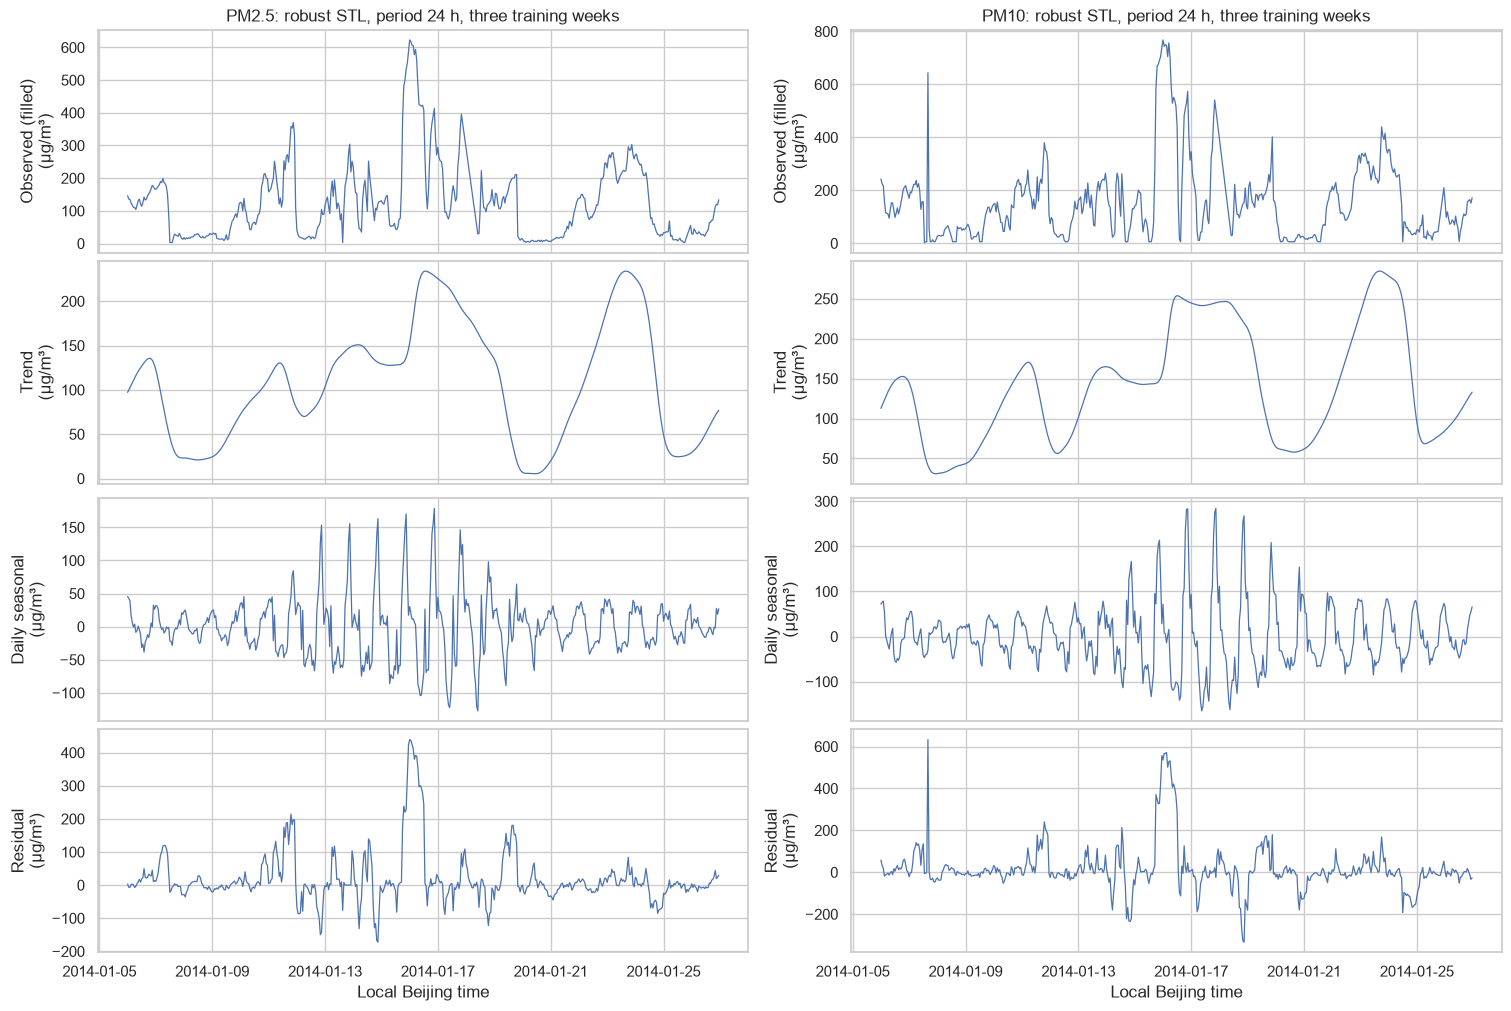

In [6]:
DAILY_PERIOD = 24
WEEKLY_PERIOD = 168
STL_SETTINGS = {"period": DAILY_PERIOD, "seasonal": 7}  # trend window: statsmodels default, 47 hours
# Robust MSTL takes about a minute per target here, so MSTL is compared with non-robust STL.
MSTL_SETTINGS = {"periods": (DAILY_PERIOD, WEEKLY_PERIOD), "stl_kwargs": {"seasonal": 7}}
# seasonal_decompose's centred moving average leaves period/2 hours undefined at each end.
EDGE_HOURS = DAILY_PERIOD // 2

decompositions = {}
decomposition_rows = []
for target in TARGET_COLUMNS:
    y = chosen_filled_training[target]
    additive = seasonal_decompose(y, model="additive", period=DAILY_PERIOD)
    multiplicative = seasonal_decompose(y, model="multiplicative", period=DAILY_PERIOD)
    decompositions[target] = {
        "additive": additive,
        "multiplicative": multiplicative,
        "stl": STL(y, **STL_SETTINGS).fit(),
        "stl_robust": STL(y, **STL_SETTINGS, robust=True).fit(),
        "mstl": MSTL(y, **MSTL_SETTINGS).fit(),
    }
    common = y.index[EDGE_HOURS:-EDGE_HOURS]
    for name, result in decompositions[target].items():
        resid = result.resid.loc[common]
        assert resid.notna().all()
        if name == "multiplicative":
            # The multiplicative residual is a ratio near 1; compare it on the log scale.
            ratio = np.log(resid).var(ddof=1) / np.log(y.loc[common]).var(ddof=1)
            scale = "log"
        else:
            ratio = resid.var(ddof=1) / y.loc[common].var(ddof=1)
            scale = "original"
        residual_acf = acf(np.log(resid) if name == "multiplicative" else resid, nlags=WEEKLY_PERIOD, fft=True)
        decomposition_rows.append(
            {
                "target": target, "method": name, "scale": scale, "hours": len(common),
                "residual_variance_ratio": float(ratio),
                "residual_acf_1": float(residual_acf[1]),
                "residual_acf_24": float(residual_acf[DAILY_PERIOD]),
                "residual_acf_168": float(residual_acf[WEEKLY_PERIOD]),
            }
        )
decomposition_comparison = pd.DataFrame(decomposition_rows).set_index(["target", "method"])
display(decomposition_comparison.round(4))

# Size of each MSTL seasonal component, as the standard deviation of the component in µg/m³.
seasonal_strength = pd.DataFrame(
    {
        target: {
            "daily_seasonal_std": float(decompositions[target]["mstl"].seasonal[f"seasonal_{DAILY_PERIOD}"].std()),
            "weekly_seasonal_std": float(decompositions[target]["mstl"].seasonal[f"seasonal_{WEEKLY_PERIOD}"].std()),
            "stl_trend_std": float(decompositions[target]["stl"].trend.std()),
            "stl_robust_trend_std": float(decompositions[target]["stl_robust"].trend.std()),
        }
        for target in TARGET_COLUMNS
    }
).T
display(seasonal_strength.round(2))

# Robust STL components are the deseasonalized and detrended basis for the anomaly section:
# robustness weights keep unusual hours in the residual instead of bending the trend.
stl_components = pd.concat(
    {
        target: pd.DataFrame(
            {
                "observed": decompositions[target]["stl_robust"].observed,
                "trend": decompositions[target]["stl_robust"].trend,
                "seasonal": decompositions[target]["stl_robust"].seasonal,
                "resid": decompositions[target]["stl_robust"].resid,
                "deseasonalized": decompositions[target]["stl_robust"].observed - decompositions[target]["stl_robust"].seasonal,
                "detrended": decompositions[target]["stl_robust"].observed - decompositions[target]["stl_robust"].trend,
                "native_observed": train[target].loc[chosen_filled_training.index].notna(),
            }
        )
        for target in TARGET_COLUMNS
    },
    axis=1,
)
processed_dir = PROCESSED_DATA_DIR / "time_series"
processed_dir.mkdir(parents=True, exist_ok=True)
stl_components_path = processed_dir / "stl_training_components.csv"
stl_components.to_csv(stl_components_path)
print(f"Saved STL training components: {stl_components_path.relative_to(PROCESSED_DATA_DIR.parent.parent)}")

# A causal seasonal feature: the mean STL daily component for each hour of day, from training only.
seasonal_profile = pd.DataFrame(
    {target: decompositions[target]["stl_robust"].seasonal.groupby(chosen_filled_training.index.hour).mean()
     for target in TARGET_COLUMNS}
).rename_axis("hour")
display(seasonal_profile.round(2).T)

window = slice("2014-01-06", "2014-01-26")
fig, axes = plt.subplots(4, 2, figsize=(15, 10), sharex="col", constrained_layout=True)
for col, target in enumerate(TARGET_COLUMNS):
    stl = decompositions[target]["stl_robust"]
    for row, (label, values) in enumerate(
        [("Observed (filled)", stl.observed), ("Trend", stl.trend), ("Daily seasonal", stl.seasonal),
         ("Residual", stl.resid)]
    ):
        axes[row, col].plot(values.loc[window], lw=0.9)
        axes[row, col].set(ylabel=f"{label}\n(µg/m³)")
    axes[0, col].set_title(f"{target}: robust STL, period 24 h, three training weeks")
    axes[-1, col].set_xlabel("Local Beijing time")
plt.show()

# Values quoted in the interpretation; the assertions guard its qualitative claims.
ratio = decomposition_comparison["residual_variance_ratio"].unstack("method")
resid_acf_24 = decomposition_comparison["residual_acf_24"].unstack("method")
resid_acf_168 = decomposition_comparison["residual_acf_168"].unstack("method")
resid_acf_1 = decomposition_comparison["residual_acf_1"].unstack("method")
assert (ratio[["additive", "stl", "stl_robust", "mstl"]].idxmin(axis=1) == "stl").all()
assert (resid_acf_24["stl"] < -0.3).all() and (resid_acf_24["stl_robust"].abs() < 0.1).all()
assert (resid_acf_168["mstl"] < -0.1).all()
assert (seasonal_strength["weekly_seasonal_std"] > seasonal_strength["daily_seasonal_std"]).all()
profile_peak = {t: int(seasonal_profile[t].idxmax()) for t in TARGET_COLUMNS}
profile_trough = {t: int(seasonal_profile[t].idxmin()) for t in TARGET_COLUMNS}
assert ((ratio["stl"] < ratio["additive"]) & (ratio["additive"] < ratio["stl_robust"])).all()
assert all(19 <= profile_peak[t] <= 23 and 12 <= profile_trough[t] <= 17 for t in TARGET_COLUMNS)

The residual variance ratio ranks the methods by how flexible their trend and seasonal components are, not by how well they recover a daily cycle. Non-robust STL has the lowest ratio, {eval}`f"{ratio.loc['PM2.5', 'stl']:.2f}"` for PM2.5 and {eval}`f"{ratio.loc['PM10', 'stl']:.2f}"` for PM10 (`decomposition_comparison`), but its residual ACF at lag 24 is {eval}`f"{resid_acf_24.loc['PM2.5', 'stl']:.2f}"` and {eval}`f"{resid_acf_24.loc['PM10', 'stl']:.2f}"`. Such a strongly negative correlation one day apart means the seasonal component copies part of each day's noise and the residual pays it back the next day: with `seasonal=7`, each hour's seasonal value is re-estimated from about a week of data, which is flexible enough to follow single pollution episodes.

Robust STL leaves more variance in the residual, {eval}`f"{ratio.loc['PM2.5', 'stl_robust']:.2f}"` and {eval}`f"{ratio.loc['PM10', 'stl_robust']:.2f}"`, and its lag-24 residual ACF is close to zero ({eval}`f"{resid_acf_24.loc['PM2.5', 'stl_robust']:.2f}"` and {eval}`f"{resid_acf_24.loc['PM10', 'stl_robust']:.2f}"`). Its robustness weights keep large episodes out of the trend and seasonal fits, so the episodes appear in the residual, as the figure shows for mid-January 2014, which is the behaviour the anomaly section needs. Classical additive decomposition sits in between ({eval}`f"{ratio.loc['PM2.5', 'additive']:.2f}"` and {eval}`f"{ratio.loc['PM10', 'additive']:.2f}"`), because its 24-hour moving-average trend follows episodes closely while its seasonal shape is fixed. The multiplicative ratio on the log scale, {eval}`f"{ratio.loc['PM2.5', 'multiplicative']:.2f}"` and {eval}`f"{ratio.loc['PM10', 'multiplicative']:.2f}"`, is not comparable with the others, although the STL figure does show the daily amplitude growing with the level during winter episodes, the pattern a multiplicative model describes.

The weekly component does not earn its place. MSTL's weekly component has a larger standard deviation than its daily component for both targets (`seasonal_strength`), even though the EDA found that the two training years' weekday profiles disagreed, and its residual ACF at lag 168 is {eval}`f"{resid_acf_168.loc['PM2.5', 'mstl']:.2f}"` and {eval}`f"{resid_acf_168.loc['PM10', 'mstl']:.2f}"`, the same overfitting signature that non-robust STL shows at lag 24. The weekly component therefore absorbs multi-day episodes rather than a repeating weekly cycle, and MSTL's longer trend window pushes more variance into the residual ({eval}`f"{ratio.loc['PM2.5', 'mstl']:.2f}"` and {eval}`f"{ratio.loc['PM10', 'mstl']:.2f}"`).

No decomposition leaves white-noise residuals: the lag-1 residual ACF ranges from {eval}`f"{resid_acf_1.min(axis=None):.2f}"` to {eval}`f"{resid_acf_1.max(axis=None):.2f}"` across methods and targets, so hour-to-hour persistence remains after trend and season are removed, and a forecast still needs recent lags. The training seasonal profile peaks at {eval}`profile_peak["PM2.5"]`:00 for PM2.5 and {eval}`profile_peak["PM10"]`:00 for PM10, with its trough in the afternoon ({eval}`profile_trough["PM2.5"]`:00 and {eval}`profile_trough["PM10"]`:00), matching the evening rise in the EDA's hour-of-day profiles. Only this hour-of-day profile enters the forecast, because it can be looked up for a future hour without reading future observations.

## Construct calendar and rolling features

Each feature row belongs to a forecast origin $t$ and predicts the next hour's value $y_{t+1}$. A feature may use anything observed at or before $t$, plus values known in advance for hour $t+1$, such as the calendar. The forecast section selects columns from the groups below.

| Group | Columns | Time used |
|---|---|---|
| Lags | $y_t, y_{t-1}, \ldots, y_{t-41}$, named `lag1` to `lag42` | Up to $t$ |
| Rolling | Mean, standard deviation, minimum, maximum, and skewness over trailing windows of 24, 168, and 720 hours | Hours $t-w+1$ to $t$ |
| Calendar | $\sin(2\pi k/T)$ and $\cos(2\pi k/T)$ for hour of day, weekday, and month; public holiday, Lunar New Year period, and heating season flags | Hour $t+1$ |
| Decomposition | Training seasonal profile at the hour of $t+1$; $y_t$ minus the profile at the hour of $t$ | Profile from training; $y_t$ |
| Covariates | SO2, NO2, CO, O3, TEMP, PRES, DEWP, RAIN, $u$, $v$, and the other target, at hour $t$ | Up to $t$ |

The cyclical encodings use $k$, the zero-based position in the cycle, and $T$, its length (24 for hours, 7 for weekdays, and 12 for months), so hour 23 and hour 0 are neighbours on the circle rather than 23 units apart. Hour of day is included because the daily cycle is the clearest recurring pattern in the EDA. Weekday stands for the working-week schedule of traffic and other activity, and month for the annual cycle of heating and weather. The EDA found that neither of these two profiles repeated well between the training years (`calendar_effect_summary` in the [EDA chapter](01_time_series_eda.ipynb)), so they are candidates rather than established effects, and the forecast ablation measures whether the calendar group helps.

Public holidays come from `holidays.China`, whose version the setup cell prints, and cover official days off only. Two further indicators mark events that plausibly change emissions. The Lunar New Year period runs from New Year's Eve to the Lantern Festival on day 15 of the first lunar month, the traditional fireworks season, starting from the first "Chinese New Year (Spring Festival)" day in the `holidays` calendar each year (`lunar_new_year_periods`). The heating-season flag marks 15 November to 15 March, Beijing's municipal heating period, when building heating is expected to add emissions.

The rolling windows cover one day, one week, and 30 days. The 24-hour window contains each hour of the day once and the 168-hour window each hour of the week once, so neither statistic depends on where in the cycle the origin falls, while the 30-day window follows the slower level changes seen in the EDA's rolling means. The EDA's 90-day window is left out because it would leave the feature undefined for the first 90 days of training.

Gaps in the inputs are handled causally: lag and covariate inputs repeat the last observation at or before $t$ for at most 3 hours, so no value is borrowed from after the origin, and longer gaps stay missing, which `RandomForestRegressor` accepts. Three hours covers the typical native gap, whose median is {eval}`int(mask_run_lengths.loc['PM2.5 native', 'median_hours'])` hour for PM2.5 (`mask_run_lengths`), while the carried value stays close to the truth, since the lag-3 training ACF is {eval}`f"{gap_reference['PM2.5'].loc[3, 'acf']:.2f}"` for PM2.5. Rolling statistics come from `trailing_window_features` in `src/preprocessing/time_series.py`. A window ending at $t$ covers hours $t-w+1$ to $t$ of the raw series, so it excludes the target hour, and the statistic is missing when fewer than 75% of the window's hours are observed or the window starts before the record. This threshold is lower than the EDA's 90% because the purposes differ: an EDA curve should show only well-covered windows, whereas a missing feature gives the forest nothing at that origin, and three quarters of a window still summarize most of the period. Retrospective interpolation appears nowhere in the feature matrix, because it reads the value after a gap.

The decomposition features carry the STL result into the forecast without its two-sided smoothing: the robust STL seasonal component is averaged by hour of day over the training interval, and that 24-value profile is looked up for any hour.

In [7]:
INPUT_FFILL_LIMIT = 3  # hours an input may be carried forward from its last observation
ROLLING_WINDOWS = [24, 168, 720]
ROLLING_MIN_SHARE = 0.75
MAX_LAG_SPAN = max(MAX_LAG_BY_TARGET.values())
FORECAST_COVARIATES = ["SO2", "NO2", "CO", "O3", "TEMP", "PRES", "DEWP", "RAIN", "u", "v"]

origin = selected.index  # forecast origin t; every target is the next hour, t + 1
target_hour = origin + pd.Timedelta(hours=1)

# Inputs observed at or before the origin, each carried forward for at most three hours.
causal_inputs = selected[TARGET_COLUMNS + FORECAST_COVARIATES].ffill(limit=INPUT_FFILL_LIMIT)

# Calendar position of the target hour, known in advance. k is zero-based within each cycle.
calendar_features = pd.DataFrame(index=origin)
for name, k, period in [("hour", target_hour.hour, 24), ("weekday", target_hour.day_of_week, 7),
                        ("month", target_hour.month - 1, 12)]:
    calendar_features[f"{name}_sin"] = np.sin(2 * np.pi * np.asarray(k) / period)
    calendar_features[f"{name}_cos"] = np.cos(2 * np.pi * np.asarray(k) / period)

china_holidays = holidays.China(years=range(origin.year.min(), origin.year.max() + 1), language="en_US")
holiday_dates = pd.DatetimeIndex(sorted(china_holidays))
# Lunar New Year period: New Year's Eve to the Lantern Festival (day 15 of the first lunar month).
lunar_new_year = pd.DatetimeIndex(
    sorted({min(d for d, n in china_holidays.items() if n == "Chinese New Year (Spring Festival)" and d.year == y)
            for y in range(origin.year.min(), origin.year.max() + 1)})
)
lunar_new_year_periods = pd.DataFrame(
    {"new_year": lunar_new_year, "start": lunar_new_year - pd.Timedelta(days=1),
     "end_inclusive": lunar_new_year + pd.Timedelta(days=14)}
)


def event_indicators(times):
    """Public holiday, Lunar New Year period, and heating season flags for each timestamp."""
    days = times.normalize()
    lunar = np.zeros(len(times), dtype=bool)
    for row in lunar_new_year_periods.itertuples():
        lunar |= (days >= row.start) & (days <= row.end_inclusive)
    # Beijing's municipal heating season, 15 November to 15 March inclusive.
    month_day = times.month * 100 + times.day
    return pd.DataFrame(
        {"public_holiday": days.isin(holiday_dates).astype(int),
         "lunar_new_year_period": lunar.astype(int),
         "heating_season": ((month_day >= 1115) | (month_day <= 315)).astype(int)},
        index=times,
    )


calendar_features = calendar_features.join(event_indicators(target_hour).set_axis(origin))

feature_columns = {}
target_frames = {}
for target in TARGET_COLUMNS:
    lags = pd.DataFrame(
        {f"{target}_lag{j}": causal_inputs[target].shift(j - 1) for j in range(1, MAX_LAG_SPAN + 1)}
    )
    rolling = trailing_window_features(selected[target], ROLLING_WINDOWS, min_share=ROLLING_MIN_SHARE)
    profile = seasonal_profile[target]
    decomposition = pd.DataFrame(
        {
            f"{target}_seasonal_next": profile.reindex(target_hour.hour).to_numpy(),
            f"{target}_deseasonalized_lag1": causal_inputs[target] - profile.reindex(origin.hour).to_numpy(),
        },
        index=origin,
    )
    other_target = [t for t in TARGET_COLUMNS if t != target]
    covariates = causal_inputs[FORECAST_COVARIATES + other_target].add_suffix("_lag1")
    target_frames[target] = pd.concat(
        [lags, rolling, calendar_features, decomposition, covariates,
         pd.DataFrame({"persistence": selected[target], "target": selected[target].shift(-1)}, index=origin)],
        axis=1,
    )
    feature_columns[target] = {
        "lags": list(lags.columns),
        "rolling": list(rolling.columns),
        "calendar": list(calendar_features.columns),
        "decomposition": list(decomposition.columns),
        "covariates": list(covariates.columns),
    }

# Each row belongs to the interval that contains its target hour t + 1.
row_interval = pd.Series(
    np.select([target_hour < VALIDATION_START, target_hour < TEST_START], ["train", "validation"], "test"),
    index=origin, name="interval",
)
row_interval.iloc[-1] = "none"  # the last origin has no target hour inside the record

feature_group_sizes = pd.DataFrame({t: {g: len(c) for g, c in groups.items()} for t, groups in feature_columns.items()})
display(feature_group_sizes)
display(lunar_new_year_periods)

# Alignment check around a gap, a cycle boundary, and a holiday in the PM2.5 frame.
alignment_columns = ["PM2.5_lag1", "PM2.5_lag2", "PM2.5_roll24_mean", "hour_sin", "hour_cos",
                     "public_holiday", "persistence", "target"]
gap_hour = train["PM2.5"].isna().idxmax()
alignment_examples = target_frames["PM2.5"].loc[
    gap_hour - pd.Timedelta(hours=2): gap_hour + pd.Timedelta(hours=4), alignment_columns
].round(3).assign(raw_value_at_origin=selected["PM2.5"], target_hour=lambda f: f.index + pd.Timedelta(hours=1))
display(alignment_examples)
holiday_boundary = pd.Timestamp("2014-09-30 21:00")
display(target_frames["PM2.5"].loc[holiday_boundary:holiday_boundary + pd.Timedelta(hours=4),
                                   ["hour_sin", "hour_cos", "public_holiday", "lunar_new_year_period"]]
        .round(3).assign(target_hour=lambda f: f.index + pd.Timedelta(hours=1)))

# No rolling feature may change when a later raw value changes.
probe = selected["PM2.5"].copy()
probe.loc[TEST_START:] = probe.loc[TEST_START:] * 10
probe_rolling = trailing_window_features(probe, ROLLING_WINDOWS, min_share=ROLLING_MIN_SHARE)
before_test = origin < TEST_START
pd.testing.assert_frame_equal(
    probe_rolling.loc[before_test], target_frames["PM2.5"].loc[before_test, feature_columns["PM2.5"]["rolling"]]
)

for target, frame in target_frames.items():
    path = processed_dir / f"forecast_features_{target}.parquet"
    frame.assign(interval=row_interval).to_parquet(path)
    print(f"Saved {target} forecast matrix {frame.shape}: {path.relative_to(PROCESSED_DATA_DIR.parent.parent)}")
candidate_feature_count = {t: sum(len(c) for c in groups.values()) for t, groups in feature_columns.items()}
for target, frame in target_frames.items():
    np.testing.assert_array_equal(frame["target"].to_numpy()[:-1], selected[target].to_numpy()[1:])
assert calendar_features.loc[holiday_boundary + pd.Timedelta(hours=2), "public_holiday"] == 1
assert calendar_features.loc[holiday_boundary + pd.Timedelta(hours=1), "public_holiday"] == 0

,PM2.5,PM10
lags,42,42
rolling,15,15
calendar,9,9
decomposition,2,2
covariates,11,11


,new_year,start,end_inclusive
0,2013-02-10,2013-02-09,2013-02-24
1,2014-01-31,2014-01-30,2014-02-14
2,2015-02-19,2015-02-18,2015-03-05
3,2016-02-08,2016-02-07,2016-02-22
4,2017-01-28,2017-01-27,2017-02-11


,PM2.5_lag1,PM2.5_lag2,PM2.5_roll24_mean,hour_sin,hour_cos,public_holiday,persistence,target,raw_value_at_origin,target_hour
timestamp,,,,,,,,,,
2013-04-15 13:00:00,165.0,149.0,124.083,-0.500,-0.866,0,165.0,164.0,165.0,2013-04-15 14:00:00
2013-04-15 14:00:00,164.0,165.0,126.500,-0.707,-0.707,0,164.0,NaN,164.0,2013-04-15 15:00:00
2013-04-15 15:00:00,164.0,164.0,126.391,-0.866,-0.500,0,NaN,108.0,NaN,2013-04-15 16:00:00
2013-04-15 16:00:00,108.0,164.0,126.174,-0.966,-0.259,0,108.0,174.0,108.0,2013-04-15 17:00:00
2013-04-15 17:00:00,174.0,108.0,128.478,-1.000,-0.000,0,174.0,199.0,174.0,2013-04-15 18:00:00
2013-04-15 18:00:00,199.0,174.0,131.304,-0.966,0.259,0,199.0,194.0,199.0,2013-04-15 19:00:00
2013-04-15 19:00:00,194.0,199.0,134.348,-0.866,0.500,0,194.0,166.0,194.0,2013-04-15 20:00:00


,hour_sin,hour_cos,public_holiday,lunar_new_year_period,target_hour
timestamp,,,,,
2014-09-30 21:00:00,-0.500,0.866,0,0,2014-09-30 22:00:00
2014-09-30 22:00:00,-0.259,0.966,0,0,2014-09-30 23:00:00
2014-09-30 23:00:00,0.000,1.000,1,0,2014-10-01 00:00:00
2014-10-01 00:00:00,0.259,0.966,1,0,2014-10-01 01:00:00
2014-10-01 01:00:00,0.500,0.866,1,0,2014-10-01 02:00:00


Saved PM2.5 forecast matrix (35064, 81): data\processed\time_series\forecast_features_PM2.5.parquet
Saved PM10 forecast matrix (35064, 81): data\processed\time_series\forecast_features_PM10.parquet


Each target has {eval}`candidate_feature_count["PM2.5"]` candidate features (`feature_group_sizes`), from which the forecast section selects a subset. The first alignment table starts two hours before the first missing PM2.5 hour in training. The origin whose target hour is missing has no target, and the next origin, whose own value is missing, has no persistence value, so both are excluded from fitting and scoring. At that second origin `PM2.5_lag1` still holds the previous observation, carried forward for one hour, and the 24-hour rolling mean averages the window's observed hours. Each row's `target` equals the raw value at the next origin, which confirms the one-hour shift.

The second table crosses midnight into the National Day holiday. Because calendar features describe the target hour, the holiday flag switches on at the origin whose target is 00:00 on 1 October, one row before the date changes at the origin itself, and the hour encoding passes smoothly from hour 23 to hour 0.

The probe at the end of the code cell changes every raw value from the test interval onward and recomputes the rolling features, and all rows before the test interval stay identical. Lags and covariates are shifts of the causally filled inputs, and the forward-fill limit means no input comes from after its origin. The matrices saved under `PROCESSED_DATA_DIR` hold every candidate column, the persistence value, the target, and each row's interval.

The Lunar New Year and heating-season indicators remain hypotheses about emissions. Two training years contain only two Lunar New Year periods, and the heating-season flag also tracks winter weather, so neither can separate an emission effect from meteorology; the calendar ablation in the forecast section measures their effect on the forecast.

## Compare anomaly detectors

Each detector defines "unusual" differently, so they flag different hours. All three are fitted on the training interval and scored on observed training hours; filled hours are not observations and are never flagged.

- Z-score on the deseasonalized series. With $d_t = y_t - S_t$ from robust STL, $z_t = (d_t - \bar{d})/s_d$, where $\bar{d}$ and $s_d$ are the training mean and standard deviation, and an hour is flagged when $|z_t| > 3$. Only 0.27% of normally distributed values lie that far out, so the rule flags clear tail values, and a heavy-tailed series produces more flags. Because each hour is compared with the whole two-year distribution, the rule flags high pollution levels.
- Isolation Forest on trailing windows. Each hour is described by its value, its change from the previous hour, and the mean, standard deviation, minimum, and maximum of the trailing 24 hours (at least 75% observed). The forest builds trees that split these features at random thresholds, and points isolated after few splits get high anomaly scores. It uses 200 trees and `random_state=RANDOM_STATE`, and `contamination=0.01` sets the threshold so that 1% of training windows are flagged. Without labelled anomalies no rate can be estimated from the data, so 1% is a declared rate: about 88 hours a year, rare enough to mean unusual and close to the share the Z-score rule flags, so the overlap compares sets of similar size.
- STL residual thresholding. With robust STL residual $R_t$, the robust z-score is $0.6745\,(R_t - \tilde{R})/\mathrm{MAD}$, where $\tilde{R}$ is the residual median and MAD the median absolute deviation from it; the factor 0.6745 puts the score on a standard-deviation scale for normal data. Hours scoring above 3.5 in absolute value are flagged, the cut-off Iglewicz and Hoaglin recommend. The rule compares each hour with its local trend and daily shape, so it flags sudden departures rather than high levels.

The comparison uses the observed hours on which every detector is defined. Overlap between flag sets $A$ and $B$ is measured by the Jaccard similarity $J(A, B) = |A \cap B| / |A \cup B|$, which is 1 for identical sets and 0 for disjoint ones, and a sensitivity table repeats each detector at neighbouring thresholds. Hours flagged by at least two detectors are grouped into episodes, merging flags up to 3 hours apart, and the largest episodes are listed by peak value.

The Z-score and STL rules use two-sided STL and are therefore retrospective, whereas Isolation Forest uses trailing windows and could run at a forecast origin once fitted. Flags are reported, not removed. Without labels, a flag shows that an hour is unusual under one detector's definition, not that the measurement is wrong; the values may record real pollution episodes, and removing flagged hours would change the forecast training and evaluation sets. Explanations for flagged episodes remain hypotheses unless outside evidence confirms them.

hours  flagged    rate
target detector                                     
PM2.5  zscore_deseasonalized  17010      259  0.0152
       isolation_forest       17010      171  0.0101
       stl_residual           17010     2700  0.1587
PM10   zscore_deseasonalized  17142      247  0.0144
       isolation_forest       17142      172  0.0100
       stl_residual           17142     1932  0.1127

rate                     \
setting                      contamination 0.005 contamination 0.01   
target detector                                                       
PM10   isolation_forest                   0.0050             0.0100   
       stl_residual                          NaN                NaN   
       zscore_deseasonalized                 NaN                NaN   
PM2.5  isolation_forest                   0.0051             0.0101   
       stl_residual                          NaN                NaN   
       zscore_deseasonalized                 NaN                NaN   

                                                                  \
setting                      contamination 0.02 |robust z| > 3.0   
target detector                                                    
PM10   isolation_forest                    0.02              NaN   
       stl_residual                         NaN           0.1255   
       zscore_deseasonalized                NaN              NaN   
PM2.5  isolation_forest                    0.02              NaN   
       stl_residual                         NaN           0.1687   
       zscore_deseasonalized                NaN              NaN   

                                                                          \
setting                      |robust z| > 3.5 |robust z| > 4.0 |z| > 2.5   
target detector                                                            
PM10   isolation_forest                   NaN              NaN       NaN   
       stl_residual                    0.1127           0.0995       NaN   
       zscore_deseasonalized              NaN              NaN    0.0263   
PM2.5  isolation_forest                   NaN              NaN       NaN   
       stl_residual                    0.1587           0.1458       NaN   
       zscore_deseasonalized              NaN              NaN    0.0266   

                                                  
setting                      |z| > 3.0 |z| > 3.5  
target detector                                   
PM10   isolation_forest            NaN       NaN  
       stl_residual                NaN       NaN  
       zscore_deseasonalized    0.0144    0.0075  
PM2.5  isolation_forest            NaN       NaN  
       stl_residual                NaN       NaN  
       zscore_deseasonalized    0.0152    0.0076

jaccard  both
target first                 second                         
PM2.5  zscore_deseasonalized isolation_forest    0.327   106
                             stl_residual        0.077   212
       isolation_forest      stl_residual        0.043   118
PM10   zscore_deseasonalized isolation_forest    0.322   102
                             stl_residual        0.106   208
       isolation_forest      stl_residual        0.057   114

hours  lunar_new_year_share  \
target detector                                             
PM2.5  all hours              17010                 0.038   
       zscore_deseasonalized    259                 0.031   
       isolation_forest         171                 0.076   
       stl_residual            2700                 0.047   
PM10   all hours              17142                 0.038   
       zscore_deseasonalized    247                 0.073   
       isolation_forest         172                 0.145   
       stl_residual            1932                 0.066   

                              heating_season_share  
target detector                                     
PM2.5  all hours                             0.328  
       zscore_deseasonalized                 0.772  
       isolation_forest                      0.912  
       stl_residual                          0.476  
PM10   all hours                             0.328  
       zscore_deseasonalized                 0.729  
       isolation_forest                      0.866  
       stl_residual                          0.503

end  agreed_hours   peak  \
target start                                                          
PM10   2013-03-09 11:00:00 2013-03-09 16:00:00             6  961.0   
       2014-01-31 01:00:00 2014-01-31 03:00:00             3  886.0   
       2014-02-14 20:00:00 2014-02-15 04:00:00             9  836.0   
       2015-02-19 01:00:00 2015-02-19 12:00:00             6  783.0   
       2014-01-15 18:00:00 2014-01-16 18:00:00            22  768.0   
       2014-03-17 09:00:00 2014-03-17 12:00:00             2  748.0   
PM2.5  2014-02-14 21:00:00 2014-02-16 15:00:00            42  704.0   
       2014-01-15 19:00:00 2014-01-16 15:00:00            19  623.0   
       2014-11-20 23:00:00 2014-11-21 22:00:00            19  557.0   
       2014-01-31 01:00:00 2014-01-31 03:00:00             3  556.0   
       2015-02-19 01:00:00 2015-02-19 05:00:00             4  525.0   
       2013-06-28 15:00:00 2013-06-28 23:00:00             9  510.0   

                                     peak_time  lunar_new_year_period  
target start                                                           
PM10   2013-03-09 11:00:00 2013-03-09 13:00:00                  False  
       2014-01-31 01:00:00 2014-01-31 01:00:00                   True  
       2014-02-14 20:00:00 2014-02-14 23:00:00                   True  
       2015-02-19 01:00:00 2015-02-19 01:00:00                   True  
       2014-01-15 18:00:00 2014-01-16 00:00:00                  False  
       2014-03-17 09:00:00 2014-03-17 09:00:00                  False  
PM2.5  2014-02-14 21:00:00 2014-02-14 23:00:00                   True  
       2014-01-15 19:00:00 2014-01-16 00:00:00                  False  
       2014-11-20 23:00:00 2014-11-21 00:00:00                  False  
       2014-01-31 01:00:00 2014-01-31 01:00:00                   True  
       2015-02-19 01:00:00 2015-02-19 01:00:00                   True  
       2013-06-28 15:00:00 2013-06-28 20:00:00                  False

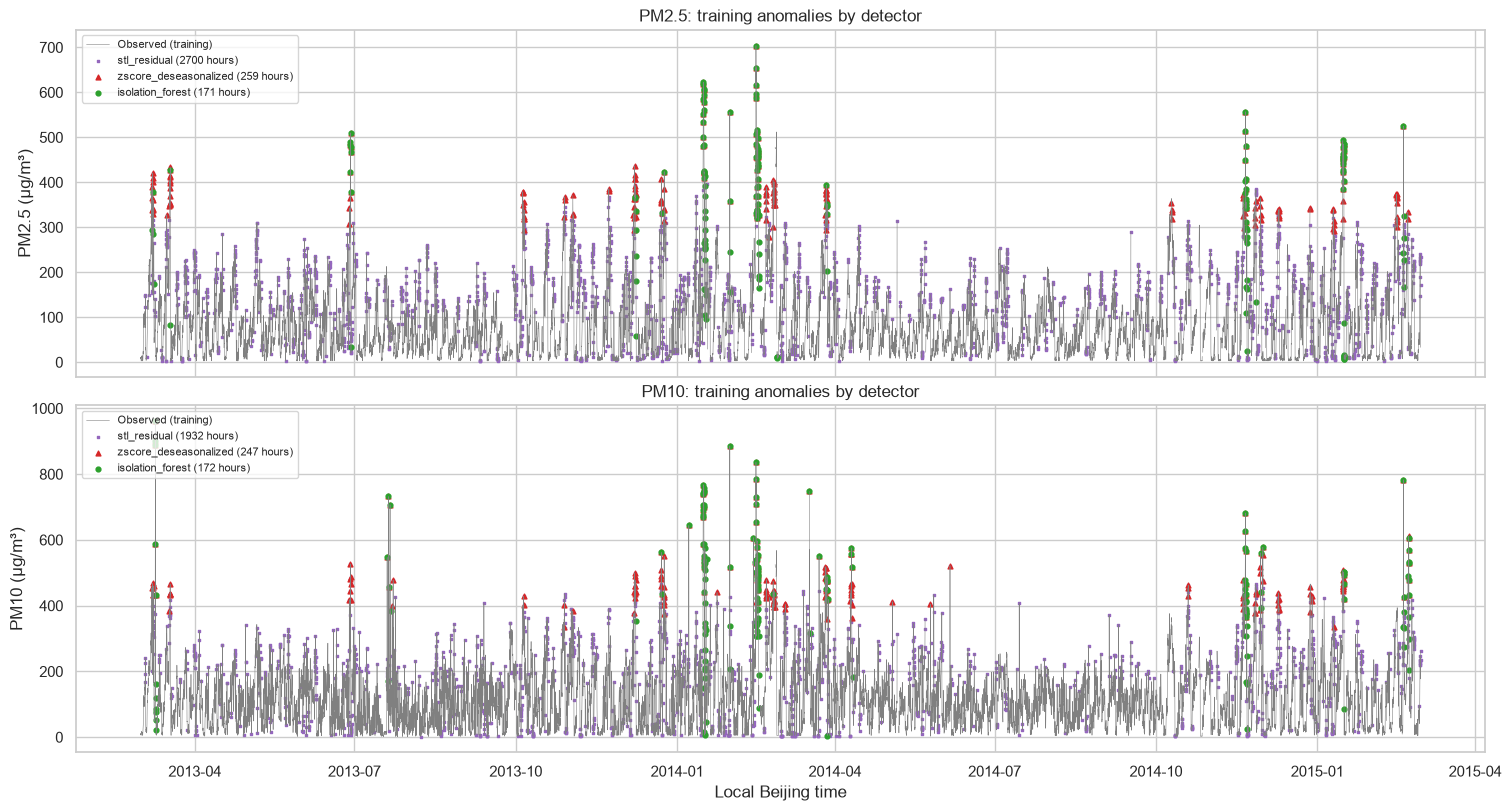

In [8]:
Z_THRESHOLD = 3.0
ROBUST_Z_THRESHOLD = 3.5
IF_CONTAMINATION = 0.01
IF_WINDOW = 24
IF_SETTINGS = {"n_estimators": 200, "random_state": RANDOM_STATE}
DETECTORS = ["zscore_deseasonalized", "isolation_forest", "stl_residual"]
# 0.6745 is the standard normal 75th percentile, so 0.6745 * x / MAD is on a standard-deviation scale.
MAD_SCALE = 0.6745


def isolation_inputs(series):
    """Current value, one-hour change, and trailing 24-hour statistics of the raw series."""
    window = trailing_window_features(series, [IF_WINDOW], min_share=ROLLING_MIN_SHARE,
                                      statistics=["mean", "std", "min", "max"])
    return window.assign(value=series, change=series.diff()).dropna()


def detector_scores(target):
    """Scores on the training hours; larger absolute values are more unusual."""
    components = stl_components[target]
    deseasonalized = components["deseasonalized"]
    zscore = (deseasonalized - deseasonalized.mean()) / deseasonalized.std(ddof=1)
    residual = components["resid"]
    mad = (residual - residual.median()).abs().median()
    robust_z = MAD_SCALE * (residual - residual.median()) / mad
    inputs = isolation_inputs(train[target])
    return zscore, robust_z, inputs


anomaly_flags = {}
anomaly_rows = []
anomaly_sensitivity_rows = []
for target in TARGET_COLUMNS:
    zscore, robust_z, inputs = detector_scores(target)
    forest = IsolationForest(contamination=IF_CONTAMINATION, **IF_SETTINGS).fit(inputs)
    # score_samples is higher for normal points; negate it so larger means more unusual.
    forest_score = pd.Series(-forest.score_samples(inputs), index=inputs.index)
    forest_cutoff = -forest.offset_
    # Compare on observed hours where every detector is defined; filled hours are not observations.
    common = stl_components[target]["native_observed"] & stl_components.index.isin(inputs.index)
    flags = pd.DataFrame(
        {
            "zscore_deseasonalized": zscore.abs() > Z_THRESHOLD,
            "isolation_forest": (forest_score > forest_cutoff).reindex(zscore.index, fill_value=False),
            "stl_residual": robust_z.abs() > ROBUST_Z_THRESHOLD,
        }
    ).loc[common]
    anomaly_flags[target] = flags
    for detector in DETECTORS:
        anomaly_rows.append({"target": target, "detector": detector, "hours": len(flags),
                             "flagged": int(flags[detector].sum()), "rate": float(flags[detector].mean())})
    # Flag rates under neighbouring settings, using the same common hours.
    for z in [2.5, 3.0, 3.5]:
        anomaly_sensitivity_rows.append({"target": target, "detector": "zscore_deseasonalized",
                                         "setting": f"|z| > {z}", "rate": float((zscore.abs() > z)[common].mean())})
    for z in [3.0, 3.5, 4.0]:
        anomaly_sensitivity_rows.append({"target": target, "detector": "stl_residual",
                                         "setting": f"|robust z| > {z}", "rate": float((robust_z.abs() > z)[common].mean())})
    for contamination in [0.005, 0.01, 0.02]:
        cutoff = np.quantile(forest_score, 1 - contamination)
        anomaly_sensitivity_rows.append(
            {"target": target, "detector": "isolation_forest", "setting": f"contamination {contamination}",
             "rate": float((forest_score > cutoff).reindex(zscore.index, fill_value=False)[common].mean())}
        )

anomaly_rates = pd.DataFrame(anomaly_rows).set_index(["target", "detector"])
anomaly_sensitivity = pd.DataFrame(anomaly_sensitivity_rows).set_index(["target", "detector", "setting"])


def jaccard(a, b):
    union = (a | b).sum()
    return float((a & b).sum() / union) if union else np.nan


anomaly_overlap = pd.DataFrame(
    [
        {"target": target, "first": first, "second": second,
         "jaccard": jaccard(flags[first], flags[second]),
         "both": int((flags[first] & flags[second]).sum())}
        for target, flags in anomaly_flags.items()
        for i, first in enumerate(DETECTORS) for second in DETECTORS[i + 1:]
    ]
).set_index(["target", "first", "second"])

# Where flags fall: shares inside the Lunar New Year period and the heating season, versus all hours.
flag_context = []
for target, flags in anomaly_flags.items():
    context = event_indicators(flags.index)
    for detector in ["all hours", *DETECTORS]:
        rows = flags.index if detector == "all hours" else flags.index[flags[detector]]
        flag_context.append({"target": target, "detector": detector, "hours": len(rows),
                             "lunar_new_year_share": float(context.loc[rows, "lunar_new_year_period"].mean()),
                             "heating_season_share": float(context.loc[rows, "heating_season"].mean())})
anomaly_context = pd.DataFrame(flag_context).set_index(["target", "detector"])

# Episodes: hours flagged by at least two detectors, merging flags up to 3 hours apart.
EPISODE_MERGE_HOURS = 3
episode_rows = []
for target, flags in anomaly_flags.items():
    agreed = flags.index[flags.sum(axis=1) >= 2].to_series()
    episode_id = agreed.diff().gt(pd.Timedelta(hours=EPISODE_MERGE_HOURS + 1)).cumsum()
    for _, hours in agreed.groupby(episode_id):
        values = train.loc[hours.iloc[0]:hours.iloc[-1], target]
        episode_rows.append({"target": target, "start": hours.iloc[0], "end": hours.iloc[-1],
                             "agreed_hours": len(hours), "peak": float(values.max()),
                             "peak_time": values.idxmax(),
                             "lunar_new_year_period": bool(event_indicators(hours.index)["lunar_new_year_period"].any())})
anomaly_episodes = (
    pd.DataFrame(episode_rows).sort_values(["target", "peak"], ascending=[True, False])
    .groupby("target").head(6).set_index(["target", "start"])
)
display(anomaly_rates.round(4))
display(anomaly_sensitivity.round(4).unstack("setting"))
display(anomaly_overlap.round(3))
display(anomaly_context.round(3))
display(anomaly_episodes)

# STL residual flags are the most numerous, so they are drawn first and smallest.
markers = {"stl_residual": ("s", "tab:purple", 4), "zscore_deseasonalized": ("^", "tab:red", 12),
           "isolation_forest": ("o", "tab:green", 12)}
fig, axes = plt.subplots(2, 1, figsize=(15, 8), sharex=True, constrained_layout=True)
for ax, target in zip(axes, TARGET_COLUMNS):
    flags = anomaly_flags[target]
    ax.plot(train.index, train[target], lw=0.4, color="grey", label="Observed (training)")
    for detector, (marker, color, size) in markers.items():
        hours = flags.index[flags[detector]]
        ax.scatter(hours, train.loc[hours, target], s=size, marker=marker, color=color,
                   label=f"{detector} ({len(hours)} hours)")
    ax.set(title=f"{target}: training anomalies by detector", ylabel=f"{target} (µg/m³)")
    ax.legend(fontsize=8, loc="upper left")
axes[-1].set_xlabel("Local Beijing time")
plt.show()

# Values quoted in the interpretation; the assertions guard its qualitative claims.
rate = anomaly_rates["rate"].unstack("detector")
overlap = anomaly_overlap["jaccard"]
context = anomaly_context
lunar_episodes = anomaly_episodes.loc[anomaly_episodes["lunar_new_year_period"]]
lunar_peak_times = ", ".join(f"{t:%Y-%m-%d %H:%M}" for t in lunar_episodes["peak_time"].drop_duplicates().sort_values())
assert (rate["stl_residual"] > 5 * rate["zscore_deseasonalized"]).all()
assert all(overlap.loc[t].idxmax() == ("zscore_deseasonalized", "isolation_forest") for t in TARGET_COLUMNS)
assert len(lunar_episodes) >= 3
assert lunar_episodes["peak_time"].dt.hour.isin([23, 0, 1]).all()
assert all(anomaly_episodes.loc[t, "peak_time"].min() >= pd.Timestamp("2013-03-01") for t in TARGET_COLUMNS)
assert set(lunar_episodes["peak_time"].dt.normalize()) <= {pd.Timestamp(d) for d in ["2014-01-31", "2014-02-14", "2015-02-19"]}

The detectors disagree about how much of the record is unusual. The Z-score rule flags {eval}`f"{rate.loc['PM2.5', 'zscore_deseasonalized']:.1%}"` of PM2.5 hours and {eval}`f"{rate.loc['PM10', 'zscore_deseasonalized']:.1%}"` of PM10 hours, Isolation Forest flags 1% by construction (`anomaly_rates`), and the STL residual rule flags {eval}`f"{rate.loc['PM2.5', 'stl_residual']:.1%}"` and {eval}`f"{rate.loc['PM10', 'stl_residual']:.1%}"`. The 3.5 cut-off assumes that most residuals are roughly normal with only a few extremes, but the robust STL residual keeps whole pollution episodes, so its distribution has heavy tails and the MAD reflects only the quiet hours. Raising the cut-off to 4 still flags {eval}`f"{anomaly_sensitivity.loc[('PM2.5', 'stl_residual', '|robust z| > 4.0'), 'rate']:.1%}"` of PM2.5 hours (`anomaly_sensitivity`), so the high rate comes from the residual distribution rather than the threshold, while the Z-score and Isolation Forest rates scale with their settings as expected.

The flag sets overlap little. The Z-score and Isolation Forest sets agree most, with Jaccard similarity {eval}`f"{overlap.loc[('PM2.5', 'zscore_deseasonalized', 'isolation_forest')]:.2f}"` for PM2.5 and {eval}`f"{overlap.loc[('PM10', 'zscore_deseasonalized', 'isolation_forest')]:.2f}"` for PM10 (`anomaly_overlap`), since both respond to high levels: Isolation Forest's inputs include the current value and the 24-hour maximum. The STL residual set overlaps each of the others with a similarity of {eval}`f"{overlap.loc['PM2.5'].xs('stl_residual', level='second').max():.2f}"` or less for PM2.5, because it flags departures from the local trend and daily shape, which can happen at any level. Each detector answers a different question, so low overlap is expected, and without labelled anomalies none of them is "correct".

Flags concentrate in winter: {eval}`f"{context.loc[('PM2.5', 'zscore_deseasonalized'), 'heating_season_share']:.0%}"` of the PM2.5 Z-score flags fall in the heating season, against {eval}`f"{context.loc[('PM2.5', 'all hours'), 'heating_season_share']:.0%}"` of all compared hours, and so do {eval}`f"{context.loc[('PM2.5', 'isolation_forest'), 'heating_season_share']:.0%}"` of the Isolation Forest flags (`anomaly_context`). Isolation Forest flags also fall in the Lunar New Year period {eval}`f"{context.loc[('PM10', 'isolation_forest'), 'lunar_new_year_share'] / context.loc[('PM10', 'all hours'), 'lunar_new_year_share']:.1f}"` times as often as expected for PM10 and {eval}`f"{context.loc[('PM2.5', 'isolation_forest'), 'lunar_new_year_share'] / context.loc[('PM2.5', 'all hours'), 'lunar_new_year_share']:.1f}"` times for PM2.5.

The episodes flagged by at least two detectors (`anomaly_episodes`) include peaks at {eval}`lunar_peak_times`. These fall on the nights of Lunar New Year 2014 and 2015 and the Lantern Festival of 2014, between 23:00 and 01:00, when fireworks are traditional; the timing fits fireworks, but without emission records it remains a hypothesis. Other large episodes, such as mid-January 2014 and late November 2014, fall in the heating season and could reflect heating emissions, stagnant weather, or both, which these data cannot separate.

## Examine Granger relationships

This extension is marked advanced in the brief and also appears in the marking rubric.

A variable $X$ Granger-causes $Y$ if past values of $X$ improve the prediction of $Y$ beyond what past values of $Y$ already provide, under a linear model with a fixed lag order $p$. The pairwise test compares

$$Y_t = c + \sum_{i=1}^{p} a_i Y_{t-i} + \sum_{i=1}^{p} b_i X_{t-i} + \varepsilon_t$$

with the restricted model that drops every $X$ term, testing $H_0: b_1 = \cdots = b_p = 0$. With residual sums of squares $\mathrm{RSS}_r$ and $\mathrm{RSS}_u$ for the restricted and unrestricted models, $n$ observations, and $k$ unrestricted coefficients,

$$F = \frac{(\mathrm{RSS}_r - \mathrm{RSS}_u)/p}{\mathrm{RSS}_u/(n-k)}.$$

The pairwise test uses `grangercausalitytests` (`ssr_ftest`). Because weather drives several pollutants at once, a pairwise relationship can come from a shared driver, so a conditional test also fits one VAR with every variable and tests whether the lags of $X$ can be dropped from the equation for $Y$ while the lags of all other variables stay (`VARResults.test_causality`, F form).

The design decisions are:

- Variables: `GRANGER_CANDIDATE_COLUMNS`, with $u$ and $v$ in place of `wd` and WSPM. RAIN is excluded if its training `zero_share` exceeds 0.9, because an hourly series that is almost always zero gives a linear lag model little to work with. The final list is `GRANGER_COLUMNS`, with $k(k-1)$ directed pairs.
- Inputs: the filled training interval, with each variable in the version the stationarity section chose, since Granger tests on non-stationary series can report spurious relationships.
- Lag order: `VAR.select_order` up to 48 hours, choosing $p$ by BIC because AIC tends to choose long orders on samples this large. Forty-eight hours spans two daily cycles, so the daily lag and its neighbours are inside the search, and since each extra lag adds a coefficient for every pair of variables, a longer cap would mainly add parameters. The selected order is compared with the cap below.
- Multiple testing: the Benjamini-Hochberg procedure at a false discovery rate of 0.05, applied separately to the pairwise and the conditional p-values.
- Effect size: the share of the restricted residual sum of squares removed by adding $X$, $1 - \mathrm{RSS}_u/\mathrm{RSS}_r$. With about 17,500 hourly observations even very small effects reach significance, so each significant result needs an effect size.

The results appear as matrices of effect sizes and as a directed graph, whose edges need both BH significance in the conditional test and an effect of at least 1%; this threshold is a declared reporting choice, not a statistical cut-off. The PM2.5 and PM10 pair needs care, because PM10 includes PM2.5 by definition and Granger tests see only lagged effects, not same-hour association. In every case, predictive Granger relationships do not establish real-world causation.

Granger variables (11): PM2.5, PM10, SO2, NO2, CO, O3, TEMP, PRES, DEWP, u, v
Hours used: 17519; lag order by BIC: 5 hours


,selected_lag
aic,26
bic,5
hqic,20
fpe,26


,count
directed_pairs,110
pairwise_significant,102
conditional_significant,85
significant_in_both,82
pairwise_only,20
conditional_edges_rss_reduction_ge_1%,18


pairwise_F  pairwise_p  pairwise_rss_reduction  conditional_F  \
cause effect                                                                  
TEMP  O3        479.0396         0.0                  0.1204       343.2103   
      PRES      203.8885         0.0                  0.0550       147.5482   
DEWP  PM10      156.1676         0.0                  0.0427       125.9883   
      PM2.5     185.3741         0.0                  0.0503       125.7898   
      NO2       191.8661         0.0                  0.0520        87.7742   
CO    PM2.5     155.5352         0.0                  0.0425        81.2086   
TEMP  CO        134.4343         0.0                  0.0370        70.1644   
PM2.5 PM10      123.6383         0.0                  0.0341        63.2937   
TEMP  SO2        40.3830         0.0                  0.0114        54.7703   
O3    NO2       109.2604         0.0                  0.0303        52.7161   
NO2   O3         51.9013         0.0                  0.0146        46.9451   
TEMP  v          99.0818         0.0                  0.0275        45.4242   
      DEWP       59.2726         0.0                  0.0167        44.8300   
DEWP  TEMP       37.3683         0.0                  0.0106        44.2731   
O3    TEMP       34.7990         0.0                  0.0098        43.3449   

              conditional_p  conditional_rss_reduction  pairwise_p_adjusted  \
cause effect                                                                  
TEMP  O3                0.0                     0.0895                  0.0   
      PRES              0.0                     0.0405                  0.0   
DEWP  PM10              0.0                     0.0348                  0.0   
      PM2.5             0.0                     0.0348                  0.0   
      NO2               0.0                     0.0245                  0.0   
CO    PM2.5             0.0                     0.0227                  0.0   
TEMP  CO                0.0                     0.0197                  0.0   
PM2.5 PM10              0.0                     0.0178                  0.0   
TEMP  SO2               0.0                     0.0154                  0.0   
O3    NO2               0.0                     0.0149                  0.0   
NO2   O3                0.0                     0.0133                  0.0   
TEMP  v                 0.0                     0.0128                  0.0   
      DEWP              0.0                     0.0127                  0.0   
DEWP  TEMP              0.0                     0.0125                  0.0   
O3    TEMP              0.0                     0.0123                  0.0   

              pairwise_significant  conditional_p_adjusted  \
cause effect                                                 
TEMP  O3                      True                     0.0   
      PRES                    True                     0.0   
DEWP  PM10                    True                     0.0   
      PM2.5                   True                     0.0   
      NO2                     True                     0.0   
CO    PM2.5                   True                     0.0   
TEMP  CO                      True                     0.0   
PM2.5 PM10                    True                     0.0   
TEMP  SO2                     True                     0.0   
O3    NO2                     True                     0.0   
NO2   O3                      True                     0.0   
TEMP  v                       True                     0.0   
      DEWP                    True                     0.0   
DEWP  TEMP                    True                     0.0   
O3    TEMP                    True                     0.0   

              conditional_significant  conditional_edge  
cause effect                                             
TEMP  O3                         True              True  
      PRES                       True              True  
DEWP  PM10                       True  

pairwise_F  pairwise_p_adjusted  pairwise_rss_reduction  \
effect cause                                                            
PM2.5  PM10      83.4955               0.0000                  0.0233   
       SO2        7.0225               0.0000                  0.0020   
       NO2       91.9722               0.0000                  0.0256   
       CO       155.5352               0.0000                  0.0425   
       O3        14.9477               0.0000                  0.0043   
       TEMP      20.3889               0.0000                  0.0058   
       PRES      11.7479               0.0000                  0.0033   
       DEWP     185.3741               0.0000                  0.0503   
       u          3.7845               0.0024                  0.0011   
       v          5.2127               0.0001                  0.0015   
PM10   PM2.5    123.6383               0.0000                  0.0341   
       SO2       26.8581               0.0000                  0.0076   
       NO2       83.7453               0.0000                  0.0234   
       CO       111.7273               0.0000                  0.0309   
       O3        13.3762               0.0000                  0.0038   
       TEMP      20.0421               0.0000                  0.0057   
       PRES      29.0630               0.0000                  0.0082   
       DEWP     156.1676               0.0000                  0.0427   
       u          3.5705               0.0037                  0.0010   
       v          1.4369               0.2172                  0.0004   

              conditional_F  conditional_p_adjusted  \
effect cause                                          
PM2.5  PM10         39.7343                  0.0000   
       SO2           1.1560                  0.3647   
       NO2          18.1000                  0.0000   
       CO           81.2086                  0.0000   
       O3            6.6765                  0.0000   
       TEMP          5.7032                  0.0001   
       PRES         10.8075                  0.0000   
       DEWP        125.7898                  0.0000   
       u             2.0030                  0.0914   
       v             2.5023                  0.0372   
PM10   PM2.5        63.2937                  0.0000   
       SO2           4.5817                  0.0006   
       NO2          23.5617                  0.0000   
       CO           31.2836                  0.0000   
       O3            5.7222                  0.0001   
       TEMP          3.1911                  0.0102   
       PRES         10.5585                  0.0000   
       DEWP        125.9883                  0.0000   
       u             9.9346                  0.0000   
       v             8.6853                  0.0000   

              conditional_rss_reduction  conditional_edge  
effect cause                                               
PM2.5  PM10                      0.0113              True  
       SO2                       0.0003             False  
       NO2                       0.0052             False  
       CO                        0.0227              True  
       O3                        0.0019             False  
       TEMP                      0.0016             False  
       PRES                      0.0031             False  
       DEWP                      0.0348              True  
       u                         0.0006             False  
       v                         0.0007             False  
PM10   PM2.5                     0.0178              True  
       SO2                       0.0013             False  
       NO2                       0.0067             False  
       CO                        0.0089             False  
       O3                        0.0016             False  
       TEMP                      0.0009             False  
       PRES                      0.0030             False  
       DEWP                      0.0348              Tru

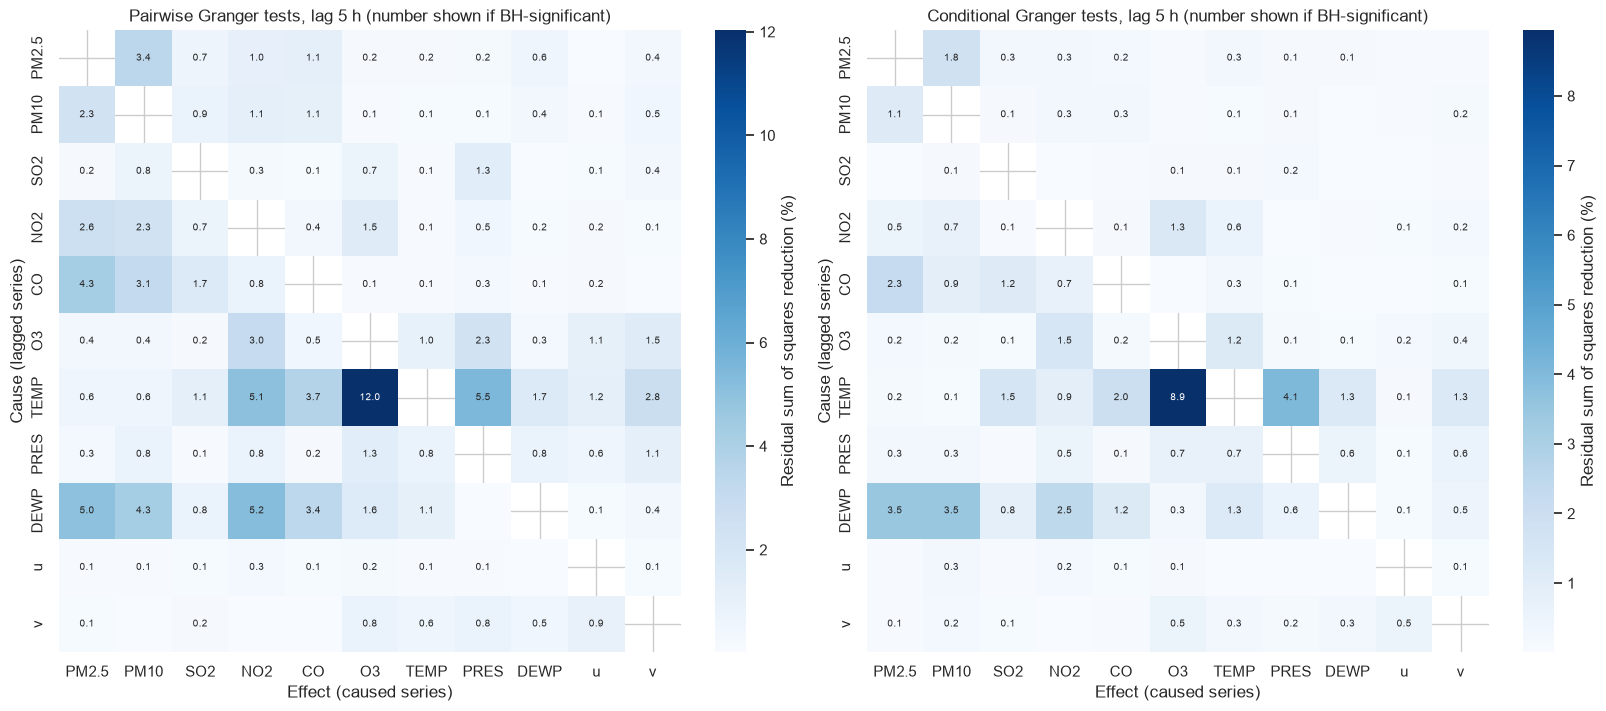

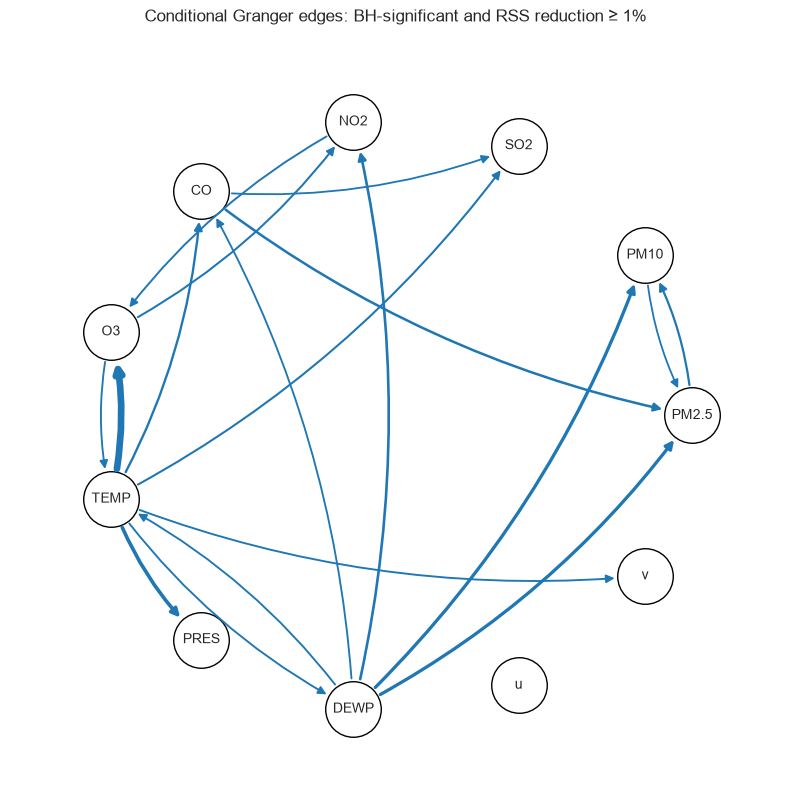

In [9]:
GRANGER_ALPHA = 0.05
GRANGER_CORRECTION = "fdr_bh"
VAR_MAX_LAGS = 48
VAR_CRITERION = "bic"
RAIN_ZERO_SHARE_LIMIT = 0.9
MIN_RSS_REDUCTION = 0.01  # 1% of the restricted residual sum of squares; drawn as a graph edge

GRANGER_COLUMNS = [
    c for c in GRANGER_CANDIDATE_COLUMNS
    if not (c == "RAIN" and training_domain.loc[c, "zero_share"] > RAIN_ZERO_SHARE_LIMIT)
]
assert all(chosen_transform[c] is not None for c in GRANGER_COLUMNS)
granger_pairs = len(GRANGER_COLUMNS) * (len(GRANGER_COLUMNS) - 1)
assert granger_pairs in granger_pair_counts.values


def stationary_version(column):
    return transformed_versions(column)[chosen_transform[column]]


granger_data = pd.concat({c: stationary_version(c) for c in GRANGER_COLUMNS}, axis=1).dropna()
lag_order = VAR(granger_data).select_order(maxlags=VAR_MAX_LAGS)
GRANGER_LAG = int(lag_order.selected_orders[VAR_CRITERION])
var_lag_orders = pd.Series(lag_order.selected_orders, name="selected_lag").to_frame()
print(f"Granger variables ({len(GRANGER_COLUMNS)}): {', '.join(GRANGER_COLUMNS)}")
print(f"Hours used: {len(granger_data)}; lag order by {VAR_CRITERION.upper()}: {GRANGER_LAG} hours")
display(var_lag_orders)

var_fit = VAR(granger_data).fit(GRANGER_LAG)
# Conditional effect size: the restricted equation drops every lag of the cause and keeps all other lags.
lagged = np.column_stack(
    [np.ones(len(granger_data) - GRANGER_LAG)]
    + [granger_data.shift(lag).to_numpy()[GRANGER_LAG:] for lag in range(1, GRANGER_LAG + 1)]
)
lag_owner = np.array([None] + [c for _ in range(GRANGER_LAG) for c in GRANGER_COLUMNS])


def residual_ss(design, response):
    coefficients, *_ = np.linalg.lstsq(design, response, rcond=None)
    return float(((response - design @ coefficients) ** 2).sum())


granger_rows = []
for effect in GRANGER_COLUMNS:
    response = granger_data[effect].to_numpy()[GRANGER_LAG:]
    full_rss = residual_ss(lagged, response)
    for cause in GRANGER_COLUMNS:
        if cause == effect:
            continue
        pairwise = grangercausalitytests(granger_data[[effect, cause]], maxlag=[GRANGER_LAG])[GRANGER_LAG]
        f_stat, f_p, *_ = pairwise[0]["ssr_ftest"]
        restricted, unrestricted = pairwise[1][:2]
        conditional = var_fit.test_causality(effect, [cause], kind="f")
        granger_rows.append(
            {
                "cause": cause, "effect": effect,
                "pairwise_F": f_stat, "pairwise_p": f_p,
                "pairwise_rss_reduction": 1 - unrestricted.ssr / restricted.ssr,
                "conditional_F": float(conditional.test_statistic), "conditional_p": float(conditional.pvalue),
                "conditional_rss_reduction": 1 - full_rss / residual_ss(lagged[:, lag_owner != cause], response),
            }
        )
granger_results = pd.DataFrame(granger_rows)
for kind in ["pairwise", "conditional"]:
    reject, adjusted, *_ = multipletests(granger_results[f"{kind}_p"], alpha=GRANGER_ALPHA, method=GRANGER_CORRECTION)
    granger_results[f"{kind}_p_adjusted"] = adjusted
    granger_results[f"{kind}_significant"] = reject
granger_results["conditional_edge"] = (
    granger_results["conditional_significant"] & granger_results["conditional_rss_reduction"].ge(MIN_RSS_REDUCTION)
)
granger_summary = pd.Series(
    {
        "directed_pairs": len(granger_results),
        "pairwise_significant": int(granger_results["pairwise_significant"].sum()),
        "conditional_significant": int(granger_results["conditional_significant"].sum()),
        "significant_in_both": int((granger_results["pairwise_significant"] & granger_results["conditional_significant"]).sum()),
        "pairwise_only": int((granger_results["pairwise_significant"] & ~granger_results["conditional_significant"]).sum()),
        f"conditional_edges_rss_reduction_ge_{MIN_RSS_REDUCTION:.0%}": int(granger_results["conditional_edge"].sum()),
    },
    name="count",
)
display(granger_summary.to_frame())
display(
    granger_results.sort_values("conditional_rss_reduction", ascending=False)
    .head(15).set_index(["cause", "effect"]).round(4)
)
target_granger = granger_results.loc[granger_results["effect"].isin(TARGET_COLUMNS)].set_index(["effect", "cause"])
display(target_granger[["pairwise_F", "pairwise_p_adjusted", "pairwise_rss_reduction", "conditional_F",
                        "conditional_p_adjusted", "conditional_rss_reduction", "conditional_edge"]].round(4))

fig, axes = plt.subplots(1, 2, figsize=(16, 7), constrained_layout=True)
for ax, kind in zip(axes, ["pairwise", "conditional"]):
    matrix = granger_results.pivot(index="cause", columns="effect", values=f"{kind}_rss_reduction") * 100
    matrix = matrix.loc[GRANGER_COLUMNS, GRANGER_COLUMNS]
    significant = granger_results.pivot(index="cause", columns="effect", values=f"{kind}_significant")
    labels = matrix.round(1).astype(str).where(significant.loc[GRANGER_COLUMNS, GRANGER_COLUMNS] == True, "")
    sns.heatmap(matrix, ax=ax, cmap="Blues", annot=labels, fmt="", annot_kws={"fontsize": 7},
                cbar_kws={"label": "Residual sum of squares reduction (%)"}, square=True)
    ax.set(title=f"{kind.capitalize()} Granger tests, lag {GRANGER_LAG} h (number shown if BH-significant)",
           xlabel="Effect (caused series)", ylabel="Cause (lagged series)")
plt.show()

# Directed graph of conditional edges: BH-significant and at least MIN_RSS_REDUCTION.
edges = granger_results.loc[granger_results["conditional_edge"]]
angles = np.linspace(0, 2 * np.pi, len(GRANGER_COLUMNS), endpoint=False)
position = {c: (np.cos(a), np.sin(a)) for c, a in zip(GRANGER_COLUMNS, angles)}
fig, ax = plt.subplots(figsize=(8, 8), constrained_layout=True)
largest = edges["conditional_rss_reduction"].max() if len(edges) else 1
for edge in edges.itertuples():
    ax.annotate(
        "", xy=position[edge.effect], xytext=position[edge.cause],
        arrowprops={"arrowstyle": "-|>", "color": "tab:blue", "shrinkA": 22, "shrinkB": 22,
                    "lw": 0.8 + 4 * edge.conditional_rss_reduction / largest,
                    "connectionstyle": "arc3,rad=0.12"},
    )
for column, (x, y) in position.items():
    ax.scatter(x, y, s=1600, facecolor="white", edgecolor="black", zorder=2)
    ax.text(x, y, column, ha="center", va="center", fontsize=10, zorder=3)
ax.set(xlim=(-1.3, 1.3), ylim=(-1.3, 1.3), aspect="equal",
       title=f"Conditional Granger edges: BH-significant and RSS reduction ≥ {MIN_RSS_REDUCTION:.0%}")
ax.axis("off")
plt.show()

# Values quoted in the interpretation; the assertions guard its qualitative claims.
excluded_from_granger = [c for c in GRANGER_CANDIDATE_COLUMNS if c not in GRANGER_COLUMNS]
granger_pct = granger_results.set_index(["cause", "effect"])[
    ["pairwise_rss_reduction", "conditional_rss_reduction"]] * 100
granger_padj = granger_results.set_index(["cause", "effect"])[["pairwise_p_adjusted", "conditional_p_adjusted"]]
strongest_edge = granger_pct["conditional_rss_reduction"].idxmax()
target_edges = {
    t: ", ".join(granger_results.loc[granger_results["effect"].eq(t) & granger_results["conditional_edge"], "cause"])
    for t in TARGET_COLUMNS
}
assert granger_pct["conditional_rss_reduction"].max() < 10
edge_pairs = set(map(tuple, granger_results.loc[granger_results["conditional_edge"], ["cause", "effect"]].to_numpy()))
assert {("PM2.5", "PM10"), ("PM10", "PM2.5"), ("DEWP", "PM2.5"), ("DEWP", "PM10")} <= edge_pairs
for target in TARGET_COLUMNS:
    into_target = granger_results.loc[granger_results["effect"].eq(target)]
    assert into_target.loc[into_target["conditional_rss_reduction"].idxmax(), "cause"] == "DEWP"
assert granger_pct.loc[("u", "PM2.5"), "pairwise_rss_reduction"] < 0.5

RAIN is excluded because {eval}`f"{training_domain.loc['RAIN', 'zero_share']:.1%}"` of its training hours are zero, which leaves {eval}`len(GRANGER_COLUMNS)` variables and {eval}`granger_pairs` directed pairs. BIC selects a VAR order of {eval}`GRANGER_LAG` hours, well inside the {eval}`VAR_MAX_LAGS`-hour cap, while AIC selects {eval}`int(var_lag_orders.loc['aic', 'selected_lag'])` (`var_lag_orders`). All tests use the BIC order.

Significance is almost universal and so says little on its own: after Benjamini-Hochberg correction, {eval}`int(granger_summary['pairwise_significant'])` of {eval}`granger_pairs` pairwise tests and {eval}`int(granger_summary['conditional_significant'])` conditional tests reject the null (`granger_summary`). With about 17,500 observations, an F test detects lagged effects that remove a fraction of a percent of the residual variance, and the effects here are small; the largest conditional effect, {eval}`strongest_edge[0]` to {eval}`strongest_edge[1]`, removes {eval}`f"{granger_pct.loc[strongest_edge, 'conditional_rss_reduction']:.1f}"`% of the restricted residual sum of squares. Only {eval}`int(granger_summary.iloc[-1])` pairs pass both the correction and the 1% effect threshold, and they form the graph.

Conditioning on the other variables removes {eval}`int(granger_summary['pairwise_only'])` pairwise relationships, which is the shared-driver problem in practice. Wind illustrates it: for PM2.5, $u$ removes {eval}`f"{granger_pct.loc[('u', 'PM2.5'), 'pairwise_rss_reduction']:.2f}"`% of the residual variance pairwise, and its conditional adjusted p-value is {eval}`f"{granger_padj.loc[('u', 'PM2.5'), 'conditional_p_adjusted']:.2f}"`. Because the Granger tests use hour-to-hour wind changes in a linear model, a weak result here does not rule out a nonlinear effect of the wind level, which the forecast can pick up.

The graph keeps {eval}`target_edges["PM2.5"]` into PM2.5 and {eval}`target_edges["PM10"]` into PM10. The strongest comes from DEWP, whose lagged changes remove {eval}`f"{granger_pct.loc[('DEWP', 'PM2.5'), 'conditional_rss_reduction']:.1f}"`% of the PM2.5 residual variance and {eval}`f"{granger_pct.loc[('DEWP', 'PM10'), 'conditional_rss_reduction']:.1f}"`% for PM10. Rising humidity often accompanies a change of air mass, and a humid, stagnant air mass is a plausible shared driver of both dew point and particle levels, an explanation the data cannot distinguish from a direct effect. The PM2.5 and PM10 edges run in both directions, which is expected because PM10 includes the PM2.5 fraction and the two series measure overlapping particles.

Three limits apply to every edge: the tests are linear and use one lag order for all pairs; differencing does not remove the daily cycle, so variables with a shared diurnal pattern, such as TEMP and O3, can predict each other partly through that cycle; and the data cover two training years at one station. The graph therefore shows which lagged variables improve linear prediction in this sample, not which variable physically causes another.

## Evaluate one-step Random Forest forecasting

The forecast comparison tests whether the preprocessed features predict better than a persistence baseline. Each row has a forecast origin $t$ and the target $y_{t+1}$, the next hour's observation, and belongs to the interval that contains its target hour. Forecasts use observed history: each test prediction reads the actual observations up to $t$, never earlier predictions. PM2.5 and PM10 each get their own model and their own persistence forecast $\hat{y}_{t+1} = y_t$.

In every interval, rows enter fitting and scoring only when $y_t$ and $y_{t+1}$ are both observed, so the model and persistence are always scored on the same origins. MAE and RMSE are in µg/m³, and the skill score $1 - \mathrm{MAE}_\text{model}/\mathrm{MAE}_\text{persistence}$ is the share of persistence error the model removes. Each target is compared with its own baseline on its own evaluation set.

The model is `RandomForestRegressor` with 200 trees, `min_samples_leaf=5`, `max_features=0.5`, `max_samples=0.5`, and `random_state=RANDOM_STATE`, fixed in advance and not tuned. A Random Forest averages regression trees fitted to bootstrap samples, so it can model nonlinear interactions between lags, calendar position, and weather, but it cannot predict values outside the range of its training targets.

The configuration is chosen on the validation interval in three steps, each keeping the previous choice:

1. Lag span. Candidates are $p \in \{1, 2, 3, 6, 12, 24\}$ plus `bic_p` and `p_reference` from the setup cell. A span $p$ uses $y_t, \ldots, y_{t-p+1}$, the lags 1 to $p$ of the target hour, with all other feature groups and covariates included.
2. Covariate set: all covariates, the Granger set, or none. The Granger set holds the variables with a conditional Granger edge into the target. The Granger tests used differenced covariates while the forecast uses their values at $t$, so the tests only propose which variables to keep.
3. Target mode. Level predicts $y_{t+1}$ directly. Difference predicts $y_{t+1} - y_t$ and adds the observed $y_t$ back, which inverts the transformation with known history and lets the forecast leave the training range.

The option with the lowest validation MAE wins each step. An ablation then removes one feature group at a time from the chosen configuration and reports the change in validation MAE, for interpretation only.

Selection uses one chronological validation year rather than cross-validation. Random k-fold splits would place hours from both sides of a validation hour in training, and with a lag-1 autocorrelation of {eval}`f"{gap_reference['PM2.5'].loc[1, 'acf']:.2f}"` for PM2.5 the model would effectively see its targets, so validation error would look better than it is. Rolling-origin cross-validation avoids that leak, but here its folds would be either too short or too few. Pollution levels depend strongly on the season through heating and winter weather, so a fold shorter than a year mostly measures its own season, while two training years allow only one or two year-long folds. A single validation year covers every season once. The cost is that each option gets one validation MAE without an estimate of its spread, so small differences between options may not be reliable.

The test interval is used once. The chosen configuration is refitted on training and validation rows together; the seasonal profile keeps its training-only estimate, and the lag, rolling, calendar, and covariate features have no fitted parameters. Test predictions are then scored against persistence.

validation_mae
target step       option                    
PM2.5  span       1                   11.008
                  2                   10.805
                  3                   10.821
                  6                   10.797
                  12                  10.791
                  24                  10.882
                  39                  10.884
       covariates all                 10.791
                  granger             11.043
                  none                11.166
       mode       level               10.791
                  difference          10.591
PM10   span       1                   17.400
                  2                   17.090
                  3                   16.957
                  6                   17.044
                  12                  17.013
                  24                  16.950
                  42                  16.895
       covariates all                 16.895
                  granger             17.661
                  none                18.185
       mode       level               16.895
                  difference          18.338

,span,groups,covariates,mode
PM2.5,12,"[rolling, calendar, decomposition, covariates]",all,difference
PM10,42,"[rolling, calendar, decomposition, covariates]",all,level


validation_mae  change_vs_chosen
target variant                                                
PM2.5  persistence                    10.988             0.397
       chosen                         10.591             0.000
       without rolling                10.380            -0.211
       without calendar               10.689             0.098
       without decomposition          10.603             0.013
       without covariates             11.330             0.740
       lags only                      10.954             0.363
PM10   persistence                    16.388            -0.507
       chosen                         16.895             0.000
       without rolling                16.259            -0.636
       without calendar               17.091             0.197
       without decomposition          17.104             0.209
       without covariates             18.185             1.290
       lags only                      17.140             0.245

origins  excluded_origins     mae    rmse
target forecast                                                
PM2.5  random_forest     8469                79  10.647  20.972
       persistence       8469                79  11.306  22.361
PM10   random_forest     8516                66  15.677  28.673
       persistence       8516                66  15.858  29.400

,mae_skill_vs_persistence,rmse_skill_vs_persistence
PM2.5,0.0583,0.0621
PM10,0.0114,0.0247


,PM2.5,PM10
0,PM2.5_lag2 (0.061),PM10_lag1 (0.483)
1,v_lag1 (0.058),PM10_deseasonalized_lag1 (0.233)
2,PM2.5_lag3 (0.045),PM10_lag2 (0.113)
3,PM10_lag1 (0.045),PM2.5_lag1 (0.049)
4,u_lag1 (0.044),PM10_lag3 (0.026)
5,PM2.5_lag1 (0.038),PM10_lag4 (0.012)
6,PM2.5_deseasonalized_lag1 (0.037),NO2_lag1 (0.004)
7,NO2_lag1 (0.036),v_lag1 (0.004)
8,PM2.5_lag4 (0.034),PM10_lag5 (0.004)
9,DEWP_lag1 (0.029),PM10_roll24_max (0.003)


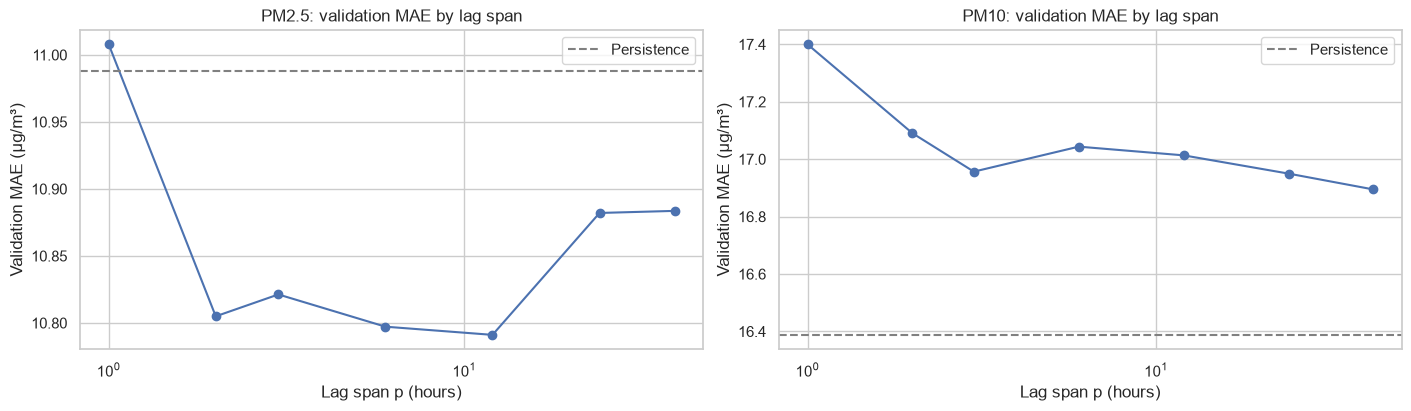

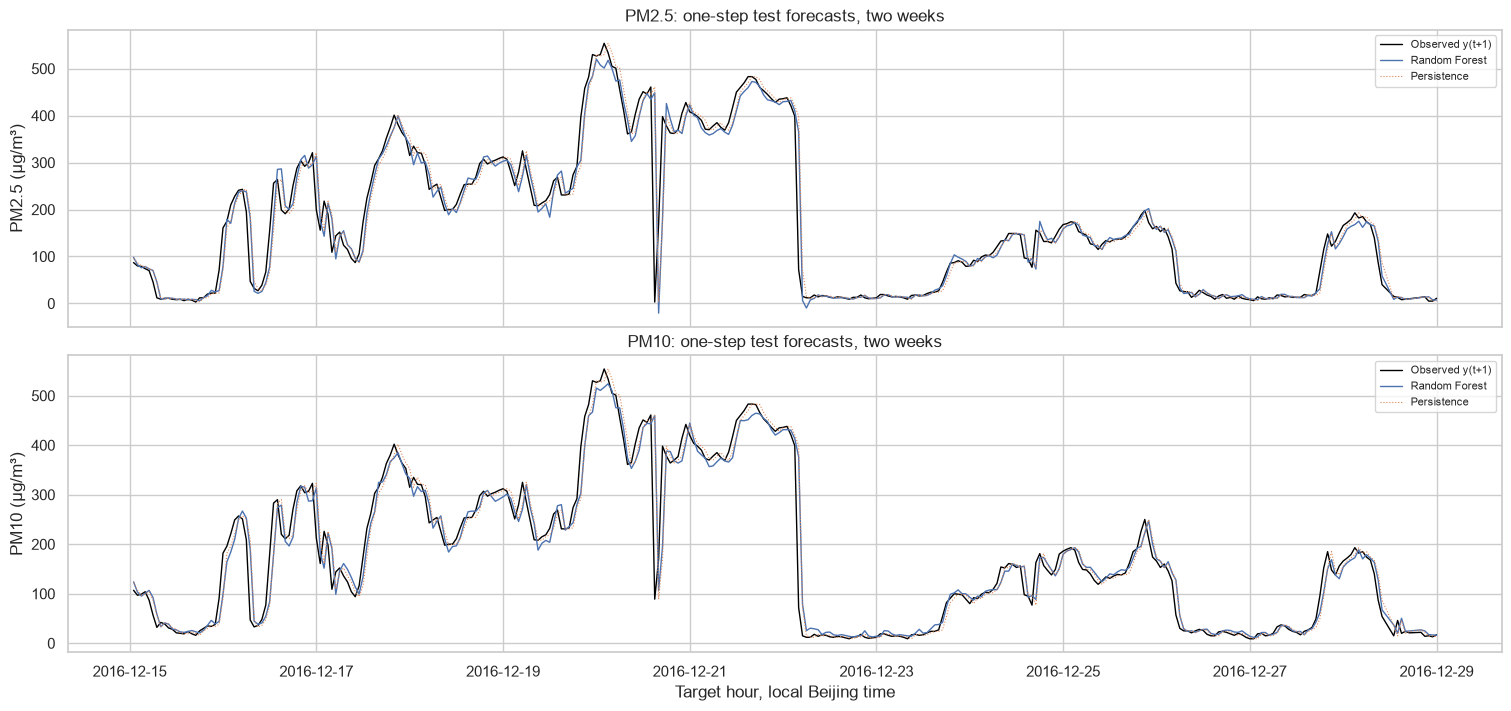

In [10]:
RF_SETTINGS = {"n_estimators": 200, "min_samples_leaf": 5, "max_features": 0.5, "max_samples": 0.5,
               "n_jobs": -1, "random_state": RANDOM_STATE}
BASE_SPANS = [1, 2, 3, 6, 12, 24]
FEATURE_GROUPS = ["rolling", "calendar", "decomposition", "covariates"]

granger_causes = {
    target: list(granger_results.loc[granger_results["effect"].eq(target) & granger_results["conditional_edge"], "cause"])
    for target in TARGET_COLUMNS
}
covariate_sets = {
    target: {"all": feature_columns[target]["covariates"],
             "granger": [f"{c}_lag1" for c in granger_causes[target]],
             "none": []}
    for target in TARGET_COLUMNS
}


def evaluation_rows(target, intervals):
    """Rows whose target hour lies in the intervals and where y_t and y_(t+1) are both observed."""
    frame = target_frames[target]
    keep = row_interval.isin(intervals) & frame["target"].notna() & frame["persistence"].notna()
    return frame.loc[keep]


def design_columns(target, config):
    columns = feature_columns[target]["lags"][: config["span"]]
    for group in config["groups"]:
        columns = columns + (covariate_sets[target][config["covariates"]] if group == "covariates"
                             else feature_columns[target][group])
    return columns


def fit_and_predict(target, config, fit_intervals, predict_interval):
    """Fit one Random Forest and return predictions in µg/m³ for the evaluation rows."""
    fit, evaluate = evaluation_rows(target, fit_intervals), evaluation_rows(target, [predict_interval])
    columns = design_columns(target, config)
    # The difference mode predicts y_(t+1) - y_t and adds back the observed y_t.
    offset_fit = fit["persistence"] if config["mode"] == "difference" else 0.0
    offset_eval = evaluate["persistence"] if config["mode"] == "difference" else 0.0
    model = RandomForestRegressor(**RF_SETTINGS).fit(fit[columns], fit["target"] - offset_fit)
    predictions = pd.Series(model.predict(evaluate[columns]), index=evaluate.index) + offset_eval
    return predictions, evaluate["target"], model, columns


validation_scores = {}


def validation_mae(target, config):
    key = (target, config["span"], tuple(config["groups"]), config["covariates"], config["mode"])
    if key not in validation_scores:
        predictions, actual, *_ = fit_and_predict(target, config, ["train"], "validation")
        validation_scores[key] = mean_absolute_error(actual, predictions)
    return validation_scores[key]


selection_rows = []
chosen_config = {}
for target in TARGET_COLUMNS:
    config = {"span": None, "groups": FEATURE_GROUPS, "covariates": "all", "mode": "level"}
    spans = sorted(set(BASE_SPANS) | {bic_reference[target], p_reference[target]})
    for step, options in [("span", spans), ("covariates", ["all", "granger", "none"]),
                          ("mode", ["level", "difference"])]:
        scores = {}
        for option in options:
            scores[option] = validation_mae(target, config | {step: option})
            selection_rows.append({"target": target, "step": step, "option": str(option),
                                   "validation_mae": scores[option]})
        config = config | {step: min(scores, key=scores.get)}
    chosen_config[target] = config

forecast_selection = pd.DataFrame(selection_rows).set_index(["target", "step", "option"])
display(forecast_selection.round(3))
display(pd.DataFrame(chosen_config).T)

# Ablation on validation: remove one feature group from the chosen configuration at a time.
ablation_rows = []
for target, config in chosen_config.items():
    validation = evaluation_rows(target, ["validation"])
    ablation_rows.append({"target": target, "variant": "persistence",
                          "validation_mae": mean_absolute_error(validation["target"], validation["persistence"])})
    ablation_rows.append({"target": target, "variant": "chosen", "validation_mae": validation_mae(target, config)})
    for group in FEATURE_GROUPS:
        reduced = config | {"groups": [g for g in config["groups"] if g != group]}
        ablation_rows.append({"target": target, "variant": f"without {group}",
                              "validation_mae": validation_mae(target, reduced)})
    lags_only = config | {"groups": []}
    ablation_rows.append({"target": target, "variant": "lags only", "validation_mae": validation_mae(target, lags_only)})
forecast_ablation = pd.DataFrame(ablation_rows).set_index(["target", "variant"])
chosen_validation_mae = forecast_ablation.xs("chosen", level="variant")["validation_mae"]
forecast_ablation["change_vs_chosen"] = (
    forecast_ablation["validation_mae"]
    - chosen_validation_mae.reindex(forecast_ablation.index.get_level_values("target")).to_numpy()
)
display(forecast_ablation.round(3))

# Final evaluation: refit on training and validation together, then score the test interval once.
test_rows = []
test_predictions = {}
final_models = {}
for target, config in chosen_config.items():
    predictions, actual, model, columns = fit_and_predict(target, config, ["train", "validation"], "test")
    test_frame = evaluation_rows(target, ["test"])
    test_predictions[target] = pd.DataFrame({"actual": actual, "random_forest": predictions,
                                             "persistence": test_frame["persistence"]})
    final_models[target] = (model, columns)
    test_targets_observed = int((row_interval.eq("test") & target_frames[target]["target"].notna()).sum())
    for name in ["random_forest", "persistence"]:
        test_rows.append(
            {"target": target, "forecast": name, "origins": len(actual),
             "excluded_origins": test_targets_observed - len(actual),
             "mae": mean_absolute_error(actual, test_predictions[target][name]),
             "rmse": root_mean_squared_error(actual, test_predictions[target][name])}
        )
forecast_test_scores = pd.DataFrame(test_rows).set_index(["target", "forecast"])
forecast_skill = pd.DataFrame(
    {
        target: {
            "mae_skill_vs_persistence": 1 - forecast_test_scores.loc[(target, "random_forest"), "mae"]
            / forecast_test_scores.loc[(target, "persistence"), "mae"],
            "rmse_skill_vs_persistence": 1 - forecast_test_scores.loc[(target, "random_forest"), "rmse"]
            / forecast_test_scores.loc[(target, "persistence"), "rmse"],
        }
        for target in TARGET_COLUMNS
    }
).T
display(forecast_test_scores.round(3))
display(forecast_skill.round(4))

feature_importance = pd.DataFrame(
    {target: pd.Series(model.feature_importances_, index=columns).nlargest(10).round(4).reset_index()
     .apply(lambda row: f"{row.iloc[0]} ({row.iloc[1]:.3f})", axis=1)
     for target, (model, columns) in final_models.items()}
)
display(feature_importance)

fig, axes = plt.subplots(1, 2, figsize=(14, 4), constrained_layout=True)
for ax, target in zip(axes, TARGET_COLUMNS):
    spans = forecast_selection["validation_mae"].xs((target, "span"), level=["target", "step"])
    ax.plot([int(s) for s in spans.index], spans.to_numpy(), "o-")
    ax.axhline(forecast_ablation.loc[(target, "persistence"), "validation_mae"], color="grey", ls="--",
               label="Persistence")
    ax.set(title=f"{target}: validation MAE by lag span", xlabel="Lag span p (hours)",
           ylabel="Validation MAE (µg/m³)", xscale="log")
    ax.legend()
plt.show()

window = slice("2016-12-15", "2016-12-28")
fig, axes = plt.subplots(2, 1, figsize=(15, 7), sharex=True, constrained_layout=True)
for ax, target in zip(axes, TARGET_COLUMNS):
    shown = test_predictions[target].loc[window]
    ax.plot(shown.index + pd.Timedelta(hours=1), shown["actual"], color="black", lw=1, label="Observed y(t+1)")
    ax.plot(shown.index + pd.Timedelta(hours=1), shown["random_forest"], lw=1, label="Random Forest")
    ax.plot(shown.index + pd.Timedelta(hours=1), shown["persistence"], lw=0.8, ls=":", label="Persistence")
    ax.set(title=f"{target}: one-step test forecasts, two weeks", ylabel=f"{target} (µg/m³)")
    ax.legend(fontsize=8)
axes[-1].set_xlabel("Target hour, local Beijing time")
plt.show()

# Values quoted in the interpretation.
selection_mae = forecast_selection["validation_mae"].sort_index()
ablation_mae = forecast_ablation["validation_mae"].sort_index()
ablation_change = forecast_ablation["change_vs_chosen"].sort_index()
test_mae = forecast_test_scores["mae"]
test_rmse = forecast_test_scores["rmse"]
span_range = {t: (selection_mae.loc[(t, "span")].min(), selection_mae.loc[(t, "span")].max()) for t in TARGET_COLUMNS}
chosen_beats_persistence_on_validation = {
    t: bool(ablation_mae.loc[(t, "chosen")] < ablation_mae.loc[(t, "persistence")]) for t in TARGET_COLUMNS
}
assert all(test_mae.loc[(t, "random_forest")] < test_mae.loc[(t, "persistence")] for t in TARGET_COLUMNS)
assert all((hi - lo) / lo < 0.05 for lo, hi in span_range.values())
assert selection_mae.loc[("PM2.5", "mode", "difference")] < selection_mae.loc[("PM2.5", "mode", "level")]
assert selection_mae.loc[("PM10", "mode", "difference")] > selection_mae.loc[("PM10", "mode", "level")]
assert chosen_beats_persistence_on_validation == {"PM2.5": True, "PM10": False}
for t in TARGET_COLUMNS:
    changes = ablation_change.loc[t].drop(["persistence", "chosen", "lags only"])
    assert changes.idxmax() == "without covariates" and changes["without rolling"] < 0
    assert changes[["without calendar", "without decomposition"]].abs().max() < 0.25
    assert selection_mae.loc[(t, "covariates", "all")] < selection_mae.loc[(t, "covariates", "granger")]
assert {"u_lag1", "v_lag1"} <= {entry.split(" ")[0] for entry in feature_importance["PM2.5"]}
assert feature_importance["PM10"].iloc[0].startswith("PM10_lag1 ")

On the test interval the Random Forest beats persistence for both targets by a small margin. For PM2.5 the test MAE is {eval}`f"{test_mae.loc[('PM2.5', 'random_forest')]:.2f}"` µg/m³ against {eval}`f"{test_mae.loc[('PM2.5', 'persistence')]:.2f}"` for persistence, a skill of {eval}`f"{forecast_skill.loc['PM2.5', 'mae_skill_vs_persistence']:.1%}"`, and the RMSE is {eval}`f"{test_rmse.loc[('PM2.5', 'random_forest')]:.2f}"` against {eval}`f"{test_rmse.loc[('PM2.5', 'persistence')]:.2f}"`. For PM10 the MAE skill is only {eval}`f"{forecast_skill.loc['PM10', 'mae_skill_vs_persistence']:.1%}"` ({eval}`f"{test_mae.loc[('PM10', 'random_forest')]:.2f}"` against {eval}`f"{test_mae.loc[('PM10', 'persistence')]:.2f}"` µg/m³). The scores cover {eval}`f"{int(forecast_test_scores.loc[('PM2.5', 'random_forest'), 'origins']):,}"` PM2.5 origins and {eval}`f"{int(forecast_test_scores.loc[('PM10', 'random_forest'), 'origins']):,}"` PM10 origins, after excluding {eval}`int(forecast_test_scores.loc[('PM2.5', 'random_forest'), 'excluded_origins'])` and {eval}`int(forecast_test_scores.loc[('PM10', 'random_forest'), 'excluded_origins'])` origins with an observed target but a missing $y_t$ (`forecast_test_scores`). Hourly particle concentrations change slowly, which makes persistence a strong baseline, and the two-week plot shows both forecasts tracking the observations with a one-hour delay at sharp rises.

The validation results are less favourable, and they matter more for judging the preprocessing. The lag span barely changes validation MAE: across all candidate spans it ranges from {eval}`f"{span_range['PM2.5'][0]:.2f}"` to {eval}`f"{span_range['PM2.5'][1]:.2f}"` µg/m³ for PM2.5 and from {eval}`f"{span_range['PM10'][0]:.2f}"` to {eval}`f"{span_range['PM10'][1]:.2f}"` for PM10, a spread under 5% of the MAE. The chosen spans, {eval}`chosen_config["PM2.5"]["span"]` hours for PM2.5 and {eval}`chosen_config["PM10"]["span"]` for PM10, would probably change with another seed or split, since a single validation year cannot show how reliable differences this small are. Spans longer than the search limit of {eval}`max(MAX_LAG_BY_TARGET.values())` hours were not tested, but with validation MAE this flat across the tested spans, nothing suggests that longer spans would help. Differencing helps PM2.5 (validation MAE {eval}`f"{selection_mae.loc[('PM2.5', 'mode', 'difference')]:.2f}"` against {eval}`f"{selection_mae.loc[('PM2.5', 'mode', 'level')]:.2f}"` in levels) and hurts PM10 ({eval}`f"{selection_mae.loc[('PM10', 'mode', 'difference')]:.2f}"` against {eval}`f"{selection_mae.loc[('PM10', 'mode', 'level')]:.2f}"`).

For PM10 the selected configuration does not beat persistence on validation ({eval}`f"{ablation_mae.loc[('PM10', 'chosen')]:.2f}"` against {eval}`f"{ablation_mae.loc[('PM10', 'persistence')]:.2f}"` µg/m³, `forecast_ablation`), so its small test advantage rests on a configuration that lost on validation and is not evidence that the PM10 preprocessing works. For PM2.5 the selected configuration does beat persistence on validation, {eval}`f"{ablation_mae.loc[('PM2.5', 'chosen')]:.2f}"` against {eval}`f"{ablation_mae.loc[('PM2.5', 'persistence')]:.2f}"`, consistent with the test result.

The ablation separates useful from harmful feature groups. Removing the covariates raises validation MAE the most, by {eval}`f"{ablation_change.loc[('PM2.5', 'without covariates')]:.2f}"` µg/m³ for PM2.5 and {eval}`f"{ablation_change.loc[('PM10', 'without covariates')]:.2f}"` for PM10, and the full covariate set also beats the Granger set ({eval}`f"{selection_mae.loc[('PM2.5', 'covariates', 'granger')]:.2f}"` against {eval}`f"{selection_mae.loc[('PM2.5', 'covariates', 'all')]:.2f}"` for PM2.5). The two wind components are among the ten most important PM2.5 features (`feature_importance`) despite forming no Granger edge, because the forest can use the wind level nonlinearly while the Granger test saw only linear effects of wind changes. Removing the calendar or decomposition features changes validation MAE by less than 0.25 µg/m³, whereas removing the rolling statistics lowers it for both targets, by {eval}`f"{-ablation_change.loc[('PM2.5', 'without rolling')]:.2f}"` and {eval}`f"{-ablation_change.loc[('PM10', 'without rolling')]:.2f}"` µg/m³. The 168- and 720-hour windows summarize weeks of history whose level shifts between years, so a forest splitting on them can fit training-period regimes that do not recur.

Feature-group selection was not among the steps declared before any result was seen. The ablation suggests that a protocol which also chose feature groups on validation would drop the rolling statistics, but that change was not applied, because the test interval had already been scored and adjusting the model afterwards would let the test result shape it. A later revision should declare a feature-group step in advance and score a fresh holdout.

Further limits apply. Impurity importances favour continuous features with many split points, so `feature_importance` shows what the forests used rather than what is necessary; for PM10, `PM10_lag1` dominates and the level model largely reproduces persistence. No test checks whether the test-MAE differences are statistically significant; a Diebold-Mariano test on the paired loss differences, with autocorrelation-robust standard errors, would be the natural next step. Finally, each test prediction uses observed history up to its origin, so these are one-hour-ahead scores that say nothing about longer horizons.

## Sources and interpretation limits

- Dataset: Zhang et al. (2017), *Cautionary tales on air-quality improvement in Beijing*, Proceedings of the Royal Society A, [DOI: 10.1098/rspa.2017.0457](https://doi.org/10.1098/rspa.2017.0457); [UCI dataset 501](https://archive.ics.uci.edu/dataset/501/beijing+multi+site+air+quality+data), CC BY 4.0. The [EDA chapter](01_time_series_eda.ipynb) records the archive checksum and the station selection.
- Ljung, G. M., and Box, G. E. P. (1978), *On a measure of lack of fit in time series models*, Biometrika 65(2), 297-303.
- Dickey, D. A., and Fuller, W. A. (1979), *Distribution of the estimators for autoregressive time series with a unit root*, Journal of the American Statistical Association 74, 427-431.
- Kwiatkowski, D., Phillips, P. C. B., Schmidt, P., and Shin, Y. (1992), *Testing the null hypothesis of stationarity against the alternative of a unit root*, Journal of Econometrics 54, 159-178.
- Phillips, P. C. B., and Perron, P. (1988), *Testing for a unit root in time series regression*, Biometrika 75(2), 335-346. Implementation: [`arch.unitroot.PhillipsPerron`](https://arch.readthedocs.io/en/latest/unitroot/generated/arch.unitroot.PhillipsPerron.html).
- Box, G. E. P., and Cox, D. R. (1964), *An analysis of transformations*, Journal of the Royal Statistical Society B 26(2), 211-252.
- Cleveland, R. B., Cleveland, W. S., McRae, J. E., and Terpenning, I. (1990), *STL: A seasonal-trend decomposition procedure based on loess*, Journal of Official Statistics 6(1), 3-73. MSTL: Bandara, K., Hyndman, R. J., and Bergmeir, C. (2021), *MSTL: A seasonal-trend decomposition algorithm for time series with multiple seasonal patterns*, [arXiv:2107.13462](https://arxiv.org/abs/2107.13462).
- Liu, F. T., Ting, K. M., and Zhou, Z.-H. (2008), *Isolation forest*, Proceedings of the IEEE International Conference on Data Mining, 413-422.
- Iglewicz, B., and Hoaglin, D. C. (1993), *How to Detect and Handle Outliers*, ASQC Quality Press.
- Granger, C. W. J. (1969), *Investigating causal relations by econometric models and cross-spectral methods*, Econometrica 37(3), 424-438.
- Benjamini, Y., and Hochberg, Y. (1995), *Controlling the false discovery rate: a practical and powerful approach to multiple testing*, Journal of the Royal Statistical Society B 57(1), 289-300.
- Breiman, L. (2001), *Random forests*, Machine Learning 45, 5-32.
- Holidays: the [`holidays`](https://pypi.org/project/holidays/) package, version printed in the setup cell. The Lunar New Year period and heating-season dates are fixed conventions stated in the feature section, not outputs of the package.

The results describe one station, two training years, one validation year, and one test year. Every hypothesis test here runs on serially dependent hourly data with many observations, so effect sizes carry more information than p-values. The forecast comparison uses a single chronological split and one fixed Random Forest configuration, and a different split or tuned settings could change the margins. AI assisted the implementation and narrative of this chapter; the student remains responsible for understanding and explaining every method and line of code at the oral exam.